# Software Engineering for AI Developers: Computer Networks for AI Apps

> **Who is this for:** AI developers who call LLM APIs, serve models over HTTP, stream tokens to a chat UI, or have ever stared at `Connection refused`, a CORS error or a timeout and not known which layer was to blame. It is also a compact revision of the classic BS "Computer Networks" course (OSI/TCP-IP, addressing, DNS, TCP/UDP, HTTP, TLS) for exams and interviews.
>
> **What you will learn:**
> - the OSI and TCP/IP models; IPv4/IPv6 addresses, private ranges, CIDR, ports, `localhost` vs. `0.0.0.0`
> - how DNS resolution works; TCP vs. UDP, with a working echo server and a UDP exchange
> - HTTP from the wire up (methods, status codes, headers, cookies, keep-alive, HTTP/1.1 vs. 2 vs. 3), including a raw request over a socket
> - TLS/HTTPS: certificates, the handshake, and why you never disable verification (demonstrated with a local self-signed certificate)
> - REST API design (resources, idempotency, pagination, versioning, errors) with a real FastAPI app
> - streaming: Server-Sent Events (how LLM token streaming works), WebSockets, gRPC/protobuf
> - CORS, latency vs. bandwidth, timeouts and retries, load balancers, reverse proxies, CDNs, rate limiting, webhooks
> - a troubleshooting checklist: `curl -v`, connection refused vs. timeout, port already in use
>
> **Prerequisites:** [Python basics](../01_Python/01_basic.ipynb); recommended: [Operating systems for developers](06_operating_systems_for_developers.ipynb) (processes, signals, file descriptors) and [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb).
>
> **Time needed:** about 3-4 hours (the notebook itself executes in about a minute).
>
> **Runs on:** CPU, no API key, **no external network**: every server and client in this notebook runs on `127.0.0.1`, on ports 8200-8299, and every server is shut down in a `finally` block.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

A computer network is how computers send each other messages, and almost every AI app depends on one: your chat page talks to your API, your API talks to the model server, and your code talks to services such as an LLM provider or a vector database. Every message needs an address (which computer), a door number called a **port** (which program on that computer), and an agreed language called a **protocol** (for example HTTP). Messages are cut into small packets, travel through many cables and routers, and are put back together at the other end. Most "it doesn't work" problems come down to a few things: the wrong address, nobody listening at that door, a security check failing, or a reply that takes too long.

Everyday examples:
- **Posting a letter:** the street address is the IP address, the flat number is the port, and the language the letter is written in is the protocol (HTTP).
- **A phone call vs. a text message:** TCP is like a phone call (you connect first, nothing gets lost, everything stays in order); UDP is like a quick text (just send it; once in a while one goes missing).
- **A live sports-score app:** goals appear as they happen, not after the match. That's streaming, the same way a chatbot shows its words as they're generated.

**Tiny example:** a chatbot answer of 200 words takes the model 10 seconds to write (20 words per second). Without streaming you stare at a spinner for 10 s. With streaming the first word appears after about 0.05 s (1/20 of a second) and you start reading straight away. The total time is the same, but it feels far faster.

**In one line:**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| IP address + port | which computer, and which program on it | `127.0.0.1:8000` for your local FastAPI server |
| HTTP | the request-and-reply language of the web | calling an LLM API with `POST /v1/chat/completions` |
| Streaming (SSE) | sending the answer piece by piece as it's made | tokens appearing one by one in a chat window |

## 0. Setup

Helpers used throughout:
- `WORK`: a temporary folder for the files we create (deleted at the end); `redact()` hides it and your home folder/username in printed output.
- `free_port()`: picks a free TCP port in 8200-8299.
- `run_server(...)`: a context manager that starts a server **as a subprocess**, waits until it accepts connections, and **always** terminates it when the block ends (even after an error). It records every process it starts so the last cell can prove none are left running.
- `client()`: an `httpx.Client` that ignores proxy settings (we only talk to localhost).

In [1]:
import os, sys, re, io, json, time, math, socket, ssl, struct, base64, hashlib, hmac, errno
import random, shutil, getpass, tempfile, threading, subprocess, ipaddress, statistics
from contextlib import contextmanager
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import httpx

random.seed(42); np.random.seed(42)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 80)

WORK = Path(tempfile.mkdtemp(prefix="net_lab_"))
_HOME, _USER = str(Path.home()), getpass.getuser()
def redact(text):
    text = str(text).replace(str(WORK), "$WORK").replace(_HOME, "~")
    return re.sub(rf"\b{re.escape(_USER)}\b", "learner", text) if _USER else text

SAFE_ENV = {"PATH": "/usr/local/bin:/usr/bin:/bin", "LANG": "C.UTF-8", "HOME": str(WORK)}  # no secrets inherited
STARTED = []                                             # every server process we launch

def free_port(lo=8200, hi=8299):
    """Return a currently free TCP port in [lo, hi] on 127.0.0.1."""
    ports = list(range(lo, hi + 1))
    random.Random().shuffle(ports)                       # random order: avoids clashing with other notebooks
    for port in ports:
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            try:
                s.bind(("127.0.0.1", port))
                return port
            except OSError:
                continue
    raise RuntimeError("no free port in 8200-8299")

@contextmanager
def run_server(args, port, timeout=60):
    """Start `args` in WORK, wait until 127.0.0.1:port accepts connections, ALWAYS stop it afterwards."""
    log_path = WORK / f"server_{port}.log"
    with open(log_path, "w") as log:
        proc = subprocess.Popen(args, cwd=WORK, stdout=log, stderr=subprocess.STDOUT, env=SAFE_ENV)
        STARTED.append(proc)
        try:
            deadline = time.monotonic() + timeout
            while True:
                if proc.poll() is not None:
                    raise RuntimeError("server exited early:\n" + redact(log_path.read_text()))
                try:
                    socket.create_connection(("127.0.0.1", port), timeout=0.2).close()
                    break                                # it accepts TCP connections: ready
                except OSError:
                    if time.monotonic() > deadline:
                        raise TimeoutError("server did not start in time")
                    time.sleep(0.1)
            yield f"http://127.0.0.1:{port}"
        finally:
            proc.terminate()                             # SIGTERM: graceful shutdown
            try:
                proc.wait(timeout=10)
            except subprocess.TimeoutExpired:
                proc.kill(); proc.wait()                 # SIGKILL if it ignores us

def uvicorn_cmd(port):
    return [sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", str(port),
            "--log-level", "warning", "--ws", "websockets-sansio"]

def client(base_url, **kw):
    return httpx.Client(base_url=base_url, trust_env=False, timeout=kw.pop("timeout", 10), **kw)

print("Python", sys.version.split()[0], "| httpx", httpx.__version__, "| sandbox:", redact(WORK))

Python 3.12.3 | httpx 0.28.1 | sandbox: $WORK


## 1. Layered models: OSI and TCP/IP

**In plain English:** networks are built in layers that each do one job, like an envelope inside an envelope inside a parcel.

**Analogy.** Sending a letter: you write the message (application), put it in an envelope with a name (transport), the post office adds a postcode route (network), and a van physically carries it (link/physical). Each layer only talks to the layer directly above and below it, so you can swap the van for a plane without rewriting the letter.

Networks are described in **layers**. The **OSI model** (7 layers) is the teaching reference; the **TCP/IP model** (4 layers) is what the internet actually runs.

| OSI layer | Job | Examples | Data unit | TCP/IP layer |
|---|---|---|---|---|
| 7 Application | what the program means | HTTP, DNS, SSH, gRPC, WebSocket | message | Application |
| 6 Presentation | encoding, encryption, compression | JSON, protobuf, TLS (often placed here), gzip | | Application |
| 5 Session | dialogues between programs | TLS sessions, RPC sessions | | Application |
| 4 Transport | process-to-process delivery via **ports** | **TCP**, **UDP**, (QUIC runs on top of UDP) | segment / datagram | Transport |
| 3 Network | host-to-host delivery across networks via **IP addresses** | IPv4, IPv6, ICMP (`ping`) | packet | Internet |
| 2 Data link | delivery on one local network via **MAC addresses** | Ethernet, Wi-Fi | frame | Link |
| 1 Physical | bits as signals | copper, fibre, radio | bits | Link |

**Encapsulation:** each layer wraps the data from the layer above with its own header:

```
Application:                                     [ HTTP request: GET /v1/models ... ]
Transport:                         [ TCP hdr: ports 51234 -> 443 ][ HTTP request ... ]
Network:              [ IP hdr: 10.0.0.5 -> 93.184.215.14 ][ TCP hdr ][ HTTP ... ]
Link:   [ Ethernet hdr: MACs ][ IP hdr ][ TCP hdr ][ HTTP ... ][ Ethernet trailer ]
```

> 🎓 **Exam tip:** "Mnemonic for OSI from layer 1 up?" *Please Do Not Throw Sausage Pizza Away* (Physical, Data link, Network, Transport, Session, Presentation, Application). And know which layer each device works at: hub (1), switch (2), router (3), load balancer (4 or 7).

When something breaks, think in layers: an HTTP 500 is a layer-7 problem (the server answered, with an error); `Connection refused` is layer 4 (the machine is reachable but nothing listens on that port); `No route to host` or a timeout can be layer 3 (or a firewall silently dropping packets).

## 2. IP addresses, CIDR and ports

**In plain English:** an IP address says which computer, a port says which program on it, and CIDR describes whole blocks of addresses.

An **IP address** identifies a network interface. **IPv4** addresses are 32 bits, written as four bytes (`192.168.1.10`): about 4.3 billion, long since exhausted. **IPv6** addresses are 128 bits, written as eight groups of hex (`2001:db8::1`, where `::` abbreviates a run of zero groups).

Important special ranges:

| Range | Meaning |
|---|---|
| `127.0.0.0/8`, `::1` | **loopback** (`localhost`): never leaves the machine |
| `10.0.0.0/8`, `172.16.0.0/12`, `192.168.0.0/16` | **private** (RFC 1918): home/office/cloud VPC networks, not routable on the internet |
| `100.64.0.0/10` | carrier-grade NAT shared space |
| `169.254.0.0/16`, `fe80::/10` | link-local; `169.254.169.254` is the **cloud metadata service** on AWS/GCP/Azure (a classic SSRF target) |
| `fc00::/7` | IPv6 unique local (private) addresses |
| `0.0.0.0` | "this host, any interface" when binding a server; "no address" otherwise |

The `ipaddress` module (standard library) knows all of this:

In [2]:
rows = []
for a in ["127.0.0.1", "10.1.2.3", "172.20.0.5", "192.168.1.10", "100.64.0.1", "169.254.169.254",
          "8.8.8.8", "::1", "fe80::1", "fd00::1", "2001:4860:4860::8888"]:
    ip = ipaddress.ip_address(a)                           # just parsing: no network access
    rows.append({"address": a, "version": ip.version, "private": ip.is_private,
                 "loopback": ip.is_loopback, "link-local": ip.is_link_local, "global": ip.is_global})
print(pd.DataFrame(rows).to_string(index=False))

             address  version  private  loopback  link-local  global
           127.0.0.1        4     True      True       False   False
            10.1.2.3        4     True     False       False   False
          172.20.0.5        4     True     False       False   False
        192.168.1.10        4     True     False       False   False
          100.64.0.1        4    False     False       False   False
     169.254.169.254        4     True     False        True   False
             8.8.8.8        4    False     False       False    True
                 ::1        6     True      True       False   False
             fe80::1        6     True     False        True   False
             fd00::1        6     True     False       False   False
2001:4860:4860::8888        6    False     False       False    True


### CIDR notation

**CIDR** (Classless Inter-Domain Routing) writes a network as `address/prefix`: the first *prefix* bits identify the network, the remaining bits identify hosts inside it.

Worked example, `192.168.1.0/24`:

```
192.168.1.10  = 11000000.10101000.00000001.00001010
/24 netmask   = 11111111.11111111.11111111.00000000  = 255.255.255.0
network part  = 192.168.1        host part = .10
```

32 - 24 = 8 host bits gives 2^8 = **256 addresses**. The first (all host bits 0) is the *network address* and the last (all 1s) the *broadcast address*, so **254 usable hosts**. (Clouds reserve a few more: AWS reserves 5 per subnet.)

This matters when you design a VPC for a GPU cluster: subnets must not overlap, and they must be big enough.

In [3]:
lan = ipaddress.ip_network("192.168.1.0/24")
print(f"{lan}: {lan.num_addresses} addresses, netmask {lan.netmask}, usable hosts {lan.num_addresses - 2}")
print("first/last usable:", lan[1], "-", lan[-2], "| broadcast:", lan.broadcast_address)

vpc = ipaddress.ip_network("10.0.0.0/16")                  # a typical cloud VPC
subnets = list(vpc.subnets(new_prefix=20))                 # carve it into /20 subnets
print(f"\n{vpc} has {vpc.num_addresses:,} addresses -> {len(subnets)} subnets of /20 ({subnets[0].num_addresses:,} each)")
for name, sn in zip(["public", "private-api", "private-gpu"], subnets):
    print(f"  {name:<12} {sn}  ({sn[0]} - {sn[-1]})")
print("\n10.0.4.17 in 10.0.0.0/20?", ipaddress.ip_address("10.0.4.17") in subnets[0])
print("10.0.4.17 in 10.0.0.0/22?", ipaddress.ip_address("10.0.4.17") in ipaddress.ip_network("10.0.0.0/22"))

192.168.1.0/24: 256 addresses, netmask 255.255.255.0, usable hosts 254
first/last usable: 192.168.1.1 - 192.168.1.254 | broadcast: 192.168.1.255

10.0.0.0/16 has 65,536 addresses -> 16 subnets of /20 (4,096 each)
  public       10.0.0.0/20  (10.0.0.0 - 10.0.15.255)
  private-api  10.0.16.0/20  (10.0.16.0 - 10.0.31.255)
  private-gpu  10.0.32.0/20  (10.0.32.0 - 10.0.47.255)

10.0.4.17 in 10.0.0.0/20? True
10.0.4.17 in 10.0.0.0/22? False


Under the hood, "is this address in that network?" is one bitwise AND. Let's implement it from scratch and check it against `ipaddress` on random inputs.

In [4]:
def ipv4_to_int(s):
    a, b, c, d = (int(x) for x in s.split("."))
    return (a << 24) | (b << 16) | (c << 8) | d             # pack 4 bytes into a 32-bit integer

def in_cidr(ip, cidr):
    net, prefix = cidr.split("/")
    mask = (0xFFFFFFFF << (32 - int(prefix))) & 0xFFFFFFFF  # e.g. /24 -> 0xFFFFFF00
    return ipv4_to_int(ip) & mask == ipv4_to_int(net) & mask

rng = random.Random(0)
for _ in range(5000):
    ip = ".".join(str(rng.randint(0, 255)) for _ in range(4))
    net = f"{rng.randint(0, 255)}.{rng.randint(0, 255)}.0.0/{rng.randint(0, 32)}"
    assert in_cidr(ip, net) == (ipaddress.ip_address(ip) in ipaddress.ip_network(net, strict=False))
print("in_cidr agrees with the ipaddress module on 5000 random cases;",
      "in_cidr('192.168.1.10', '192.168.1.0/24') =", in_cidr("192.168.1.10", "192.168.1.0/24"))

in_cidr agrees with the ipaddress module on 5000 random cases; in_cidr('192.168.1.10', '192.168.1.0/24') = True


### Ports

An IP address finds the machine; a **port** (16-bit number, 0-65535) finds the program on it. A connection is identified by the 4-tuple (source IP, source port, destination IP, destination port), which is how one server port can hold thousands of client connections.

| Range | Name | Notes |
|---|---|---|
| 0-1023 | well-known / system ports | binding needs root (or `CAP_NET_BIND_SERVICE`) on Linux |
| 1024-49151 | registered ports | most dev servers live here |
| 49152-65535 | dynamic / ephemeral (IANA) | Linux picks client-side ports from its own range (below) |

| Port | Usual service | Port | Usual service |
|---|---|---|---|
| 22 | SSH | 5432 | PostgreSQL |
| 53 | DNS | 6379 | Redis |
| 80 / 443 | HTTP / HTTPS | 6006 | TensorBoard |
| 8000 / 8080 | dev web servers (uvicorn default 8000) | 8888 | Jupyter |
| 5000 | Flask, MLflow UI | 11434 | Ollama |

In [5]:
rng_file = Path("/proc/sys/net/ipv4/ip_local_port_range")
if rng_file.exists():
    lo, hi = map(int, rng_file.read_text().split())
    print(f"this Linux kernel picks ephemeral (client) ports from {lo}-{hi}")

# localhost vs a specific address: a socket bound to 127.0.0.1 only accepts connections to 127.0.0.1
port = free_port()
srv = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
try:
    srv.bind(("127.0.0.1", port)); srv.listen()
    print("server bound to", ("127.0.0.1", port))
    for target in ["127.0.0.1", "127.0.0.2"]:              # both are loopback addresses on Linux
        try:
            socket.create_connection((target, port), timeout=1).close()
            print(f"  connect to {target}:{port} -> accepted")
        except OSError as e:
            print(f"  connect to {target}:{port} -> {type(e).__name__}: {e.strerror}")
finally:
    srv.close()

this Linux kernel picks ephemeral (client) ports from 32768-60999
server bound to ('127.0.0.1', 8279)
  connect to 127.0.0.1:8279 -> accepted
  connect to 127.0.0.2:8279 -> ConnectionRefusedError: Connection refused


**What just happened?** The listening socket was bound to the *specific* address `127.0.0.1`, so a connection to `127.0.0.2` (also loopback on Linux) was refused. That's the same reason:

| Bind address | Who can connect | Use it for |
|---|---|---|
| `127.0.0.1` (localhost) | only programs on this machine | development, admin endpoints, local model servers |
| `0.0.0.0` (all IPv4 interfaces) | anyone who can reach any of the machine's addresses | servers **inside a container** (the container's `127.0.0.1` is its own private loopback, so a server bound there is unreachable through `-p 8000:8000`), production behind a firewall |
| `::` | all IPv6 (and usually IPv4) interfaces | dual-stack servers |

> ⚠️ **Common mistake:** running `uvicorn main:app --host 0.0.0.0` on a laptop on café Wi-Fi exposes your unauthenticated dev API (and Jupyter, if started the same way) to everyone on that network. Use `127.0.0.1` unless you need outside access.

## 3. DNS: turning names into addresses

**In plain English:** DNS is the phone book that turns names like `api.example.com` into IP addresses.

**DNS** (Domain Name System) is the internet's phone book: it maps names like `api.openai.com` to IP addresses. It's a distributed, hierarchical, cached database.

```
your program ──getaddrinfo("api.example.com")──> stub resolver (OS: /etc/hosts, then the configured DNS server)
                                                   │ cache miss
                                                   v
                                        recursive resolver (ISP, 1.1.1.1, 8.8.8.8, or your VPC's resolver)
                       1. "who handles .com?"  ──> root server      ──> "ask the .com servers"
                       2. "who handles example.com?" ──> .com TLD server ──> "ask ns1.example.com"
                       3. "A record for api.example.com?" ──> authoritative server ──> 93.184.215.14, TTL 300
                                                   │ answer cached for TTL seconds at every level
                                                   v
                                        your program connects to 93.184.215.14:443
```

| Record | Maps | Example |
|---|---|---|
| **A** / **AAAA** | name → IPv4 / IPv6 address | `api.example.com → 93.184.215.14` |
| **CNAME** | name → another name (alias) | `www → example.com` |
| **MX** | domain → mail servers | |
| **TXT** | arbitrary text (domain verification, SPF) | |
| **NS** | which servers are authoritative | |
| **SRV**, **HTTPS** | service location / connection hints (e.g. that HTTP/3 is available) | |

**TTL** (time to live) says how long answers may be cached. That's why a DNS change can take minutes to hours to reach everyone, and why "it works on my machine" can be a stale cache. Tools: `dig api.example.com`, `nslookup`, `getent hosts name`.

The standard-library call every client uses is `socket.getaddrinfo`. To keep the notebook offline we only resolve `localhost` (answered locally from `/etc/hosts`, no DNS server involved).

In [6]:
seen = []
for family, type_, proto, canonname, sockaddr in socket.getaddrinfo("localhost", 8200, type=socket.SOCK_STREAM):
    entry = (family.name, sockaddr[0])
    if entry not in seen:
        seen.append(entry)
for fam, addr in seen:
    print(f"localhost -> {addr:<10} ({fam})")

localhost -> 127.0.0.1  (AF_INET)


**What just happened?** `localhost` resolved to `127.0.0.1`, read from `/etc/hosts` without asking any DNS server. On many systems it resolves to **both** `::1` (IPv6) and `127.0.0.1` (IPv4), depending on `/etc/hosts`. Clients try the addresses in order, so a server listening only on `127.0.0.1` can then see a failed IPv6 attempt first; some clients then wait for a timeout before falling back. If `localhost` is mysteriously slow, try `127.0.0.1` explicitly. That's why this notebook always uses `127.0.0.1`.

> 🎓 **Interview tip:** "What happens when you type a URL and press Enter?" Walk the layers: parse URL → DNS lookup (cache, `/etc/hosts`, resolver) → TCP handshake (or QUIC for HTTP/3) → TLS handshake and certificate check → HTTP request → server (load balancer → app) → response → rendering. Mention caching at every step.

## 4. TCP vs. UDP

**In plain English:** TCP is a reliable phone call between two programs; UDP is a quick note that might get lost.

The transport layer delivers data between *programs* (ports). The two classic protocols make opposite trade-offs:

| | **TCP** | **UDP** |
|---|---|---|
| connection | yes: 3-way handshake first | no: just send datagrams |
| reliability | lost data is retransmitted; arrives **in order**, no duplicates | packets may be lost, duplicated or reordered |
| message boundaries | **no**: a continuous **byte stream** | **yes**: each datagram arrives whole (or not at all) |
| flow / congestion control | yes (slows down when the receiver or network is overloaded) | no (application's job) |
| overhead / latency | higher (handshake, ACKs, head-of-line blocking) | lower |
| used by | HTTP/1.1, HTTP/2, SSH, databases, gRPC | DNS, video calls, games, **QUIC (HTTP/3)** |

**TCP three-way handshake** (connection set-up costs one round trip before any data flows):

```
client                                   server (listening)
  |  SYN  seq=x                    ---->  |
  |  <---- SYN-ACK  seq=y, ack=x+1        |
  |  ACK  ack=y+1                  ---->  |      connection ESTABLISHED
  |  data ...  <---------------------->   |      every byte is numbered and acknowledged
  |  FIN  ---->   <---- ACK, FIN  ---->   |      closing; the closer waits in TIME_WAIT
```

Let's build a tiny TCP echo server (in a background thread) and a client. Because TCP has no message boundaries, we use a common **framing** rule: one message = one line ending in `\n`.

In [7]:
def tcp_echo_server(listener, stop):
    listener.settimeout(0.2)                           # wake up regularly to check `stop`
    while not stop.is_set():
        try:
            conn, addr = listener.accept()             # blocks until a client connects
        except socket.timeout:
            continue
        with conn, conn.makefile("rwb") as stream:     # file-like wrapper around the socket
            for line in stream:                        # read one '\n'-terminated message at a time
                stream.write(b"echo: " + line.upper())
                stream.flush()

port = free_port()
listener = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
listener.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)   # allow quick re-use of the port
listener.bind(("127.0.0.1", port)); listener.listen()
stop = threading.Event()
server_thread = threading.Thread(target=tcp_echo_server, args=(listener, stop), daemon=True)
server_thread.start()
try:
    with socket.create_connection(("127.0.0.1", port), timeout=5) as sock:   # SYN, SYN-ACK, ACK
        print("client", sock.getsockname(), "->", "server", sock.getpeername())
        stream = sock.makefile("rwb")
        for msg in ["hello", "tokens are bytes", "bye"]:
            stream.write(msg.encode() + b"\n"); stream.flush()
            print("  sent", repr(msg), "| got back", repr(stream.readline().decode().strip()))
        stream.close()
finally:
    stop.set(); server_thread.join(timeout=2); listener.close()
print("server thread stopped:", not server_thread.is_alive())

client ('127.0.0.1', 51892) -> server ('127.0.0.1', 8297)
  sent 'hello' | got back 'echo: HELLO'
  sent 'tokens are bytes' | got back 'echo: TOKENS ARE BYTES'
  sent 'bye' | got back 'echo: BYE'
server thread stopped: True


**What just happened?** The client got a random **ephemeral port** from the OS, the handshake happened inside `create_connection`, and each line came back transformed. Now the byte-stream property: two separate `send` calls can arrive as **one** chunk, so a protocol must define where messages end (newlines, a length prefix, or HTTP's `Content-Length`).

In [8]:
port = free_port()
listener = socket.socket(); listener.bind(("127.0.0.1", port)); listener.listen()
try:
    client_sock = socket.create_connection(("127.0.0.1", port), timeout=5)
    conn, _ = listener.accept()
    client_sock.sendall(b"hello")                      # message 1
    client_sock.sendall(b"world")                      # message 2
    time.sleep(0.1)                                    # let both arrive before the server reads
    print("server's single recv() returned:", conn.recv(1024))
    conn.close(); client_sock.close()
finally:
    listener.close()

server's single recv() returned: b'helloworld'


Now **UDP**: no connection, no handshake; each `sendto` is one datagram and each `recvfrom` returns exactly one datagram with the sender's address.

In [9]:
port = free_port()
udp_server = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)     # SOCK_DGRAM = UDP
udp_client = socket.socket(socket.AF_INET, socket.SOCK_DGRAM)
try:
    udp_server.bind(("127.0.0.1", port)); udp_server.settimeout(2); udp_client.settimeout(2)
    for metric in [b"gpu_util=0.93", b"tokens_per_s=812", b"queue_len=4"]:
        udp_client.sendto(metric, ("127.0.0.1", port))             # fire and forget
    for _ in range(3):
        data, addr = udp_server.recvfrom(2048)                     # one whole datagram per call
        print("server got datagram", data, "from port", addr[1])
        udp_server.sendto(b"ack:" + data.split(b"=")[0], addr)
    print("client got replies:", [udp_client.recvfrom(2048)[0] for _ in range(3)])
finally:
    udp_server.close(); udp_client.close()

server got datagram b'gpu_util=0.93' from port 41097
server got datagram b'tokens_per_s=812' from port 41097
server got datagram b'queue_len=4' from port 41097
client got replies: [b'ack:gpu_util', b'ack:tokens_per_s', b'ack:queue_len']


**What just happened?** Three datagrams arrived as three separate messages (boundaries preserved). On loopback nothing is lost, but over a real network UDP gives **no guarantee**: that's acceptable for metrics (StatsD sends exactly this kind of `name=value` datagram) or live audio, where a late packet is useless anyway. DNS uses UDP because one small question and answer fit in a single datagram.

## 5. HTTP

**In plain English:** HTTP is the simple request-and-reply language spoken by browsers, APIs and LLM services.

**HTTP** is a text-based (in HTTP/1.1) request/response protocol on top of TCP. A request and a response on the wire:

```
POST /v1/chat/completions HTTP/1.1          <- request line: METHOD, path, version
Host: api.example.com                        <- headers: "Name: value"
Content-Type: application/json
Authorization: Bearer sk-...
Content-Length: 52
                                             <- blank line (\r\n) ends the headers
{"model": "tiny", "messages": [{"role": "user"}]}   <- body

HTTP/1.1 200 OK                              <- status line: version, code, reason
Content-Type: application/json
Content-Length: 87

{"id": "chat-1", "choices": [...]}
```

| Method | Purpose | Safe? | Idempotent? | Body? |
|---|---|---|---|---|
| GET | read a resource | yes | yes | no |
| HEAD | GET without the body (check existence/size) | yes | yes | no |
| POST | create / run an action | no | **no** | yes |
| PUT | replace a resource completely | no | yes | yes |
| PATCH | modify part of a resource | no | not necessarily | yes |
| DELETE | remove a resource | no | yes | rarely |
| OPTIONS | ask what's allowed (CORS preflight) | yes | yes | no |

**Safe** = doesn't change server state. **Idempotent** = doing it twice has the same effect on the server as doing it once (so it can be retried safely).

| Code | Meaning | Typical cause in an AI API |
|---|---|---|
| 200 OK | success | |
| 201 Created | resource created (add a `Location` header) | registered a new model |
| 204 No Content | success, empty body | DELETE |
| 301 / 308 | moved permanently (308 keeps the method) | old API path |
| 302 / 307 | temporary redirect (307 keeps the method) | |
| 304 Not Modified | your cached copy is still valid | `ETag` / `If-None-Match` |
| 400 Bad Request | malformed request | invalid JSON |
| 401 Unauthorized | **not authenticated** (no/invalid credentials) | missing API key |
| 403 Forbidden | authenticated but **not allowed** | key lacks access to that model |
| 404 Not Found | no such resource | wrong model ID |
| 405 Method Not Allowed | path exists, method doesn't | GET on a POST-only endpoint |
| 409 Conflict | conflicts with current state | name already taken |
| 413 Content Too Large | body too big | uploading a huge file |
| 422 Unprocessable Content (older name: Unprocessable Entity) | well-formed but invalid | FastAPI/pydantic validation errors |
| 429 Too Many Requests | rate limited (see `Retry-After`) | exceeded tokens/minute |
| 500 Internal Server Error | bug on the server | unhandled exception |
| 502 Bad Gateway | proxy got a bad answer from upstream | model server crashed behind nginx |
| 503 Service Unavailable | temporarily overloaded / down | model still loading |
| 504 Gateway Timeout | proxy gave up waiting for upstream | generation took longer than the proxy timeout |

Rule of thumb: **4xx = the client should change something; 5xx = the server has a problem** (retrying later may help).

| Header | Direction | Purpose |
|---|---|---|
| `Host` | request | which site (many sites share one IP); mandatory in HTTP/1.1 |
| `Content-Type` / `Accept` | both / request | body format sent / formats wanted (`application/json`, `text/event-stream`) |
| `Authorization` | request | credentials, e.g. `Bearer <token>` |
| `Content-Length` / `Transfer-Encoding: chunked` | both | where the body ends (known length / streamed in chunks) |
| `Cache-Control`, `ETag` | response | caching rules / version tag of the resource |
| `Set-Cookie` / `Cookie` | response / request | the server stores a small value in the browser, which sends it back |
| `Retry-After` | response | how long to wait (with 429/503) |
| `User-Agent` | request | client name/version |

**Cookies** carry state (e.g. a session ID) over stateless HTTP. Secure them with attributes: `HttpOnly` (JavaScript can't read it, which limits XSS damage), `Secure` (HTTPS only), `SameSite=Lax/Strict` (not sent on most cross-site requests, which limits CSRF), plus `Max-Age`/`Expires`, `Path`, `Domain`.

**Keep-alive**: opening a TCP (and TLS) connection costs round trips, so HTTP/1.1 keeps connections open **by default** and reuses them for further requests (`Connection: close` opts out; HTTP/1.0 closed by default). Reusing one `httpx.Client` / `requests.Session` is what makes this work in Python (measured in Section 11).

| | HTTP/1.1 | HTTP/2 | HTTP/3 |
|---|---|---|---|
| standard | 1997; current RFC 9112 (2022) | 2015; current RFC 9113 (2022) | RFC 9114 (2022) |
| transport | TCP | TCP | **QUIC over UDP** (RFC 9000) |
| format | text | binary frames | binary frames |
| concurrency | one request at a time per connection (pipelining exists but is effectively unused), so browsers open ~6 connections per host | many **multiplexed streams** on one connection | multiplexed streams, each independent |
| head-of-line blocking | yes, at the HTTP level | solved at HTTP level, but **one lost TCP packet stalls all streams** | **no transport-level HOL blocking** (loss affects only its own stream) |
| header compression | none | HPACK | QPACK |
| encryption | optional (HTTPS = HTTP over TLS) | browsers require TLS (`h2`) | **always** TLS 1.3, built into QUIC |
| other | | server push (now deprecated; Chrome removed it) | faster set-up (1-RTT, 0-RTT resumption), **connection migration** when your IP changes (Wi-Fi → 4G) |

The meaning of methods, status codes and headers is the same in all three (RFC 9110, "HTTP Semantics"); only the wire format differs. gRPC requires HTTP/2.

## 6. A raw HTTP request over a socket

**In plain English:** underneath it all, an HTTP request is just a few lines of text sent over a connection.

Let's prove HTTP is "just text over TCP". We serve a folder with Python's built-in `http.server` (as a subprocess on 127.0.0.1, port 8200-8299) and talk to it with a bare socket.

In [10]:
site = WORK / "site"; site.mkdir()
(site / "hello.txt").write_text("Hello from a tiny web server!\n")
(site / "model_card.json").write_text(json.dumps({"name": "tiny-bert", "params": 4_400_000}))

def raw_http(port, request_text):
    """Send raw request text over TCP and return the raw response bytes."""
    with socket.create_connection(("127.0.0.1", port), timeout=5) as s:
        s.sendall(request_text.encode())
        chunks = []
        while chunk := s.recv(4096):                   # read until the server closes the connection
            chunks.append(chunk)
    return b"".join(chunks)

def parse_response(raw):
    """Split raw HTTP response bytes into (status line, headers dict, body)."""
    head, _, body = raw.partition(b"\r\n\r\n")         # headers end at the first blank line
    lines = head.decode("iso-8859-1").split("\r\n")
    headers = {}
    for line in lines[1:]:
        name, _, value = line.partition(":")
        headers[name.strip().lower()] = value.strip()  # header names are case-insensitive
    return lines[0], headers, body

port = free_port()
with run_server([sys.executable, "-m", "http.server", str(port), "--bind", "127.0.0.1",
                 "--directory", str(site)], port):
    raw = raw_http(port, "GET /hello.txt HTTP/1.1\r\nHost: 127.0.0.1\r\nConnection: close\r\n\r\n")
    print("----- raw response bytes -----")
    print(re.sub(r"Date: .*", "Date: <now>", raw.decode()))     # hide the changing timestamp
    status, headers, body = parse_response(raw)
    print("----- parsed -----\nstatus:", status, "| Content-Type:", headers["content-type"],
          "| Content-Length:", headers["content-length"], "| body:", body)
    status404, _, _ = parse_response(raw_http(port, "GET /missing.bin HTTP/1.1\r\nHost: x\r\n\r\n"))
    status_head, h, b = parse_response(raw_http(port, "HEAD /model_card.json HTTP/1.1\r\nHost: x\r\n\r\n"))
    print("missing file ->", status404)
    print("HEAD request ->", status_head, "| Content-Length:", h["content-length"], "| body bytes:", len(b))

----- raw response bytes -----
HTTP/1.0 200 OK
Server: SimpleHTTP/0.6 Python/3.12.3
Date: <now>
Content-type: text/plain
Content-Length: 30
Last-Modified: Tue, 27 Oct 2026 08:46:44 GMT

Hello from a tiny web server!

----- parsed -----
status: HTTP/1.0 200 OK | Content-Type: text/plain | Content-Length: 30 | body: b'Hello from a tiny web server!\n'
missing file -> HTTP/1.0 404 File not found
HEAD request -> HTTP/1.0 200 OK | Content-Length: 40 | body bytes: 0


**What just happened?** We typed the request by hand and got back exactly the anatomy shown above: a status line, `Name: value` headers, a blank line, and the body (whose size is given by `Content-Length`). Notice the server wrote `Content-type` with a small "t": header **names are case-insensitive**, so our parser lower-cases them (httpx and requests do the same). The 404 came back as a normal HTTP response, and `HEAD` returned the headers (including the size) with an empty body. Note that `http.server` answers with `HTTP/1.0` and closes the connection after each response; that's why our `recv` loop could simply read until the connection closed. The server process was terminated when the `with` block ended.

> ⚠️ **Never use `python -m http.server` in production:** it's single-purpose, has no security hardening and serves every file in the folder. For real services use uvicorn/gunicorn behind nginx or a managed load balancer.

## 7. TLS and HTTPS

**In plain English:** HTTPS wraps HTTP in encryption and uses certificates to prove you're talking to the real server.

**HTTPS = HTTP inside a TLS connection.** **TLS** (Transport Layer Security; TLS 1.3 is RFC 8446, 2018; TLS 1.0/1.1 are deprecated) gives three guarantees:

1. **Confidentiality**: nobody on the path (Wi-Fi, ISP, a proxy) can read the traffic.
2. **Integrity**: nobody can modify it undetected.
3. **Authentication**: you're talking to the real `api.example.com`, not an impostor. This one depends entirely on **certificate verification**.

A **certificate** (X.509) binds a public key to names (in the *Subject Alternative Name* field), signed by a **certificate authority (CA)**. Your OS/Python ships a list of trusted root CAs; a server sends its certificate plus intermediates, forming a **chain of trust**:

```
Root CA (pre-installed in your OS / certifi)   signs ->   Intermediate CA   signs ->   api.example.com (leaf)
```

Public certificates are short-lived (for example, Let's Encrypt certificates last 90 days by default, and CA/Browser Forum rules are reducing the maximum lifetime of all public TLS certificates step by step to 47 days by 2029), so renew them automatically.

**TLS 1.3 handshake** (conceptually, one round trip):

```
client                                                          server
  | ClientHello: versions, ciphers, key share (ECDHE), SNI name ---> |
  | <--- ServerHello: chosen cipher, key share                       |
  | <--- {Certificate chain, CertificateVerify (signed), Finished}   |   (already encrypted)
  | client CHECKS: chain to a trusted root? name matches? dates valid? signature valid?
  | {Finished} --->  then encrypted HTTP requests/responses          |
```

Both sides derive the same session keys from the key shares (Diffie-Hellman), so even a recorded conversation can't be decrypted later (*forward secrecy*).

**Why you must never disable verification** (`verify=False` in requests/httpx, `ssl._create_unverified_context()`, `CERT_NONE`): encryption without authentication protects you from nobody, because an attacker in the middle simply presents *their own* certificate, decrypts everything (your API keys included), and re-encrypts it to the real server. If you're behind a corporate proxy with its own CA, point your client at that CA bundle (`verify="/path/corp-ca.pem"`, or `SSL_CERT_FILE` / `REQUESTS_CA_BUNDLE`) instead.

Python's default client context does the right thing:

In [11]:
ctx = ssl.create_default_context()
print("verify_mode:", ctx.verify_mode.name, "| check_hostname:", ctx.check_hostname,
      "| minimum TLS version:", ctx.minimum_version.name)
print("OpenSSL linked into Python:", ssl.OPENSSL_VERSION.split()[0:2])

verify_mode: CERT_REQUIRED | check_hostname: True | minimum TLS version: MINIMUM_SUPPORTED
OpenSSL linked into Python: ['OpenSSL', '3.0.13']


Now a local demonstration: we create a **self-signed** certificate for `localhost` with the `openssl` command-line tool (optional: skipped if it isn't installed), run a tiny TLS server, and connect three ways.

In [12]:
def tls_server(listener, ctx, stop):
    listener.settimeout(0.2)
    while not stop.is_set():
        try:
            conn, _ = listener.accept()
        except socket.timeout:
            continue
        conn.settimeout(3)
        try:
            with ctx.wrap_socket(conn, server_side=True) as tls:    # TLS handshake (server side)
                tls.recv(1024)
                tls.sendall(b"HTTP/1.1 200 OK\r\nContent-Length: 14\r\nConnection: close\r\n\r\nhello, TLS 1.3")
        except (ssl.SSLError, OSError):
            pass                                                    # the client rejected us: handshake aborted

def tls_get(port, client_ctx, server_hostname):
    with socket.create_connection(("127.0.0.1", port), timeout=3) as raw:
        with client_ctx.wrap_socket(raw, server_hostname=server_hostname) as tls:   # handshake + verification
            tls.sendall(b"GET / HTTP/1.1\r\nHost: localhost\r\n\r\n")
            body = tls.recv(1024).partition(b"\r\n\r\n")[2]
            return f"OK: {tls.version()}, cipher {tls.cipher()[0]}, body {body!r}"

if shutil.which("openssl"):
    r = subprocess.run(["openssl", "req", "-x509", "-newkey", "ec", "-pkeyopt", "ec_paramgen_curve:prime256v1",
                        "-nodes", "-keyout", "key.pem", "-out", "cert.pem", "-days", "1", "-subj", "/CN=localhost",
                        "-addext", "subjectAltName=DNS:localhost,IP:127.0.0.1"],
                       cwd=WORK, env=SAFE_ENV, capture_output=True, text=True)
    assert r.returncode == 0, r.stderr
    server_ctx = ssl.SSLContext(ssl.PROTOCOL_TLS_SERVER)
    server_ctx.load_cert_chain(WORK / "cert.pem", WORK / "key.pem")
    port = free_port()
    listener = socket.socket(); listener.bind(("127.0.0.1", port)); listener.listen()
    stop = threading.Event()
    t = threading.Thread(target=tls_server, args=(listener, server_ctx, stop), daemon=True); t.start()
    try:
        trusting_ctx = ssl.create_default_context(cafile=WORK / "cert.pem")   # trust exactly our cert
        cases = [("default trust store, name 'localhost'", ssl.create_default_context(), "localhost"),
                 ("our cert trusted, name 'localhost'", trusting_ctx, "localhost"),
                 ("our cert trusted, name 'api.example.com'", trusting_ctx, "api.example.com")]
        for label, cctx, name in cases:
            try:
                result = tls_get(port, cctx, name)
            except ssl.SSLCertVerificationError as e:
                result = f"REJECTED: {e.verify_message}"
            print(f"{label:<42} -> {result}")
    finally:
        stop.set(); t.join(timeout=3); listener.close()
else:
    print("openssl not installed: skipping the local TLS demo (the explanation above still applies)")

default trust store, name 'localhost'      -> REJECTED: self-signed certificate
our cert trusted, name 'localhost'         -> OK: TLSv1.3, cipher TLS_AES_256_GCM_SHA384, body b'hello, TLS 1.3'
our cert trusted, name 'api.example.com'   -> REJECTED: Hostname mismatch, certificate is not valid for 'api.example.com'.


**What just happened?**
1. With the normal trust store, the client **rejected** the server: a self-signed certificate isn't signed by any trusted CA. This is exactly what you'd see if someone intercepted your traffic.
2. When we explicitly trusted our certificate (the right way to handle private CAs), the handshake succeeded with **TLS 1.3** and an AEAD cipher.
3. With the same trusted certificate but a different expected name, verification failed with a **hostname mismatch**: a valid certificate for the wrong site is still the wrong site.

## 8. REST API design

**In plain English:** a REST API gives each thing its own web address and uses the HTTP verbs to read, create, change or delete it.

**REST** (Representational State Transfer) is a style for HTTP APIs: you expose **resources** (nouns) at URLs and use the HTTP **methods** (verbs) to act on them.

| Action | Method + path | Success code |
|---|---|---|
| list models | `GET /v1/models?limit=3&cursor=...` | 200 |
| create a model | `POST /v1/models` | 201 + `Location: /v1/models/7` |
| read one | `GET /v1/models/7` | 200 (404 if missing) |
| replace | `PUT /v1/models/7` | 200 |
| delete | `DELETE /v1/models/7` | 204 |
| an action that isn't CRUD | `POST /v1/models/7:deploy` or `POST /v1/deployments` | 202 Accepted if it runs in the background |

Design rules that save pain later:
- **Nouns, plural, lowercase**: `/v1/models/7/versions`, not `/getModelVersions?id=7`.
- **Idempotency**: GET/PUT/DELETE are idempotent by definition, so clients may retry them. POST isn't: a retried "create" (or "charge card", or "start a $500 fine-tuning job") after a timeout can do the work twice. Accept an **`Idempotency-Key`** header: the first request with a key does the work, repeats return the stored result.
- **Pagination**: never return unbounded lists. *Offset* pagination (`?offset=40&limit=20`) is simple but slow on big tables and skips/duplicates items when data changes; **cursor** pagination (`?cursor=<last id seen>`) is stable and fast.
- **Versioning**: put the major version in the path (`/v1/`) or a header; never break `v1` clients, add `v2` instead.
- **One error format** everywhere: **RFC 9457 "Problem Details"** (`application/problem+json`, which replaced RFC 7807) with `type`, `title`, `status`, `detail`, plus your own fields.

We now write a small FastAPI app (a model registry) into the temp folder. It also contains the endpoints for the streaming, CORS, timeout, retry and rate-limit demos later on. The rate limiter lives in its own module, explained in Section 11.

In [13]:
(WORK / "ratelimit.py").write_text("""
class TokenBucket:
    # Token bucket: allows bursts of up to `capacity` requests, refilled at `rate` tokens per second.
    def __init__(self, capacity, rate):
        self.capacity, self.rate = capacity, rate
        self.tokens, self.last = float(capacity), None     # start full

    def allow(self, now):
        # returns (allowed?, seconds until the next token)
        if self.last is not None:                          # refill for the time that has passed
            self.tokens = min(self.capacity, self.tokens + (now - self.last) * self.rate)
        self.last = now
        if self.tokens >= 1:
            self.tokens -= 1                               # spend one token on this request
            return True, 0.0
        return False, (1 - self.tokens) / self.rate
""".lstrip())

APP_SOURCE = """
import asyncio, json, math, time
from http import HTTPStatus
from fastapi import FastAPI, Header, HTTPException, Query, Response, WebSocket, WebSocketDisconnect
from fastapi.exceptions import RequestValidationError
from fastapi.middleware.cors import CORSMiddleware
from fastapi.responses import JSONResponse, StreamingResponse
from pydantic import BaseModel, Field
from starlette.exceptions import HTTPException as StarletteHTTPException
from ratelimit import TokenBucket

app = FastAPI(title="Model Registry API", version="1.0.0")

# CORS: only our (pretend) front-end at http://localhost:3000 may call us from a browser
app.add_middleware(CORSMiddleware, allow_origins=["http://localhost:3000"],
                   allow_methods=["GET", "POST", "PUT", "DELETE"],
                   allow_headers=["Content-Type", "Authorization", "Idempotency-Key"], max_age=600)

# ---- one error format everywhere: RFC 9457 problem details
def problem(status, detail, headers=None, **extra):
    body = {"type": "about:blank", "title": HTTPStatus(status).phrase, "status": status, "detail": detail, **extra}
    return JSONResponse(body, status_code=status, headers=headers, media_type="application/problem+json")

@app.exception_handler(StarletteHTTPException)
async def on_http_error(request, exc):
    return problem(exc.status_code, exc.detail, headers=getattr(exc, "headers", None))

@app.exception_handler(RequestValidationError)
async def on_validation_error(request, exc):
    errors = [{"field": ".".join(str(p) for p in e["loc"][1:]), "message": e["msg"]} for e in exc.errors()]
    return problem(422, "request validation failed", errors=errors)

# ---- the resource
class ModelIn(BaseModel):
    name: str = Field(min_length=1, max_length=50)
    task: str = Field(pattern="^(classification|generation|embedding)$")
    accuracy: float | None = Field(default=None, ge=0, le=1)

MODELS = {}            # id -> model (an in-memory "database")
IDEMPOTENCY = {}       # Idempotency-Key -> id it created
NEXT_ID = [1]

@app.get("/health")
def health():
    return {"status": "ok"}

@app.get("/v1/models")
def list_models(limit: int = Query(3, ge=1, le=100), cursor: int = 0):
    ids = sorted(i for i in MODELS if i > cursor)          # cursor = last id the client has seen
    page = [MODELS[i] for i in ids[:limit]]
    return {"data": page, "next_cursor": page[-1]["id"] if len(ids) > limit else None}

@app.post("/v1/models", status_code=201)
def create_model(model: ModelIn, response: Response, idempotency_key: str | None = Header(default=None)):
    if idempotency_key in IDEMPOTENCY:                     # a retry: return the original result
        item = MODELS[IDEMPOTENCY[idempotency_key]]
        response.headers["Idempotent-Replayed"] = "true"
    else:
        item = {"id": NEXT_ID[0], **model.model_dump()}
        MODELS[item["id"]] = item
        NEXT_ID[0] += 1
        if idempotency_key:
            IDEMPOTENCY[idempotency_key] = item["id"]
    response.headers["Location"] = f"/v1/models/{item['id']}"
    return item

@app.get("/v1/models/{model_id}")
def get_model(model_id: int):
    if model_id not in MODELS:
        raise HTTPException(404, f"model {model_id} does not exist")
    return MODELS[model_id]

@app.put("/v1/models/{model_id}")
def replace_model(model_id: int, model: ModelIn):
    if model_id not in MODELS:
        raise HTTPException(404, f"model {model_id} does not exist")
    MODELS[model_id] = {"id": model_id, **model.model_dump()}
    return MODELS[model_id]

@app.delete("/v1/models/{model_id}", status_code=204)
def delete_model(model_id: int):
    if MODELS.pop(model_id, None) is None:
        raise HTTPException(404, f"model {model_id} does not exist")
    return Response(status_code=204)

# ---- streaming: Server-Sent Events, the way LLM APIs stream tokens
REPLY = "Paging gives every process its own private address space ."
@app.get("/v1/generate/stream")
async def generate_stream(prompt: str = "hi", delay: float = 0.05):
    async def events():
        for i, token in enumerate(REPLY.split(" ")):
            await asyncio.sleep(delay)                     # pretend the model computes the next token
            yield f"id: {i}\\nevent: token\\ndata: {json.dumps({'token': token})}\\n\\n"
        yield "event: done\\ndata: [DONE]\\n\\n"
    return StreamingResponse(events(), media_type="text/event-stream",
                             headers={"Cache-Control": "no-cache", "X-Accel-Buffering": "no"})

# ---- WebSocket chat: full duplex, either side may send at any time
@app.websocket("/v1/ws/chat")
async def chat(ws: WebSocket):
    await ws.accept()
    try:
        while True:
            msg = await ws.receive_text()
            if msg == "bye":
                await ws.close(code=1000)
                break
            for token in f"you said: {msg}".split(" "):
                await ws.send_text(json.dumps({"type": "token", "token": token}))
            await ws.send_text(json.dumps({"type": "done"}))
    except WebSocketDisconnect:
        pass

# ---- endpoints for the timeout / retry / rate-limit demos
@app.get("/v1/slow")
async def slow(seconds: float = 2.0):
    await asyncio.sleep(seconds)
    return {"waited": seconds}

FLAKY = {}
@app.get("/v1/flaky")
def flaky(x_client_id: str = Header(default="anon")):
    FLAKY[x_client_id] = FLAKY.get(x_client_id, 0) + 1
    if FLAKY[x_client_id] <= 2:                            # the first two calls fail
        raise HTTPException(503, "model server is warming up")
    return {"ok": True, "attempt": FLAKY[x_client_id]}

BUCKETS = {}
@app.get("/v1/limited")
def limited(x_client_id: str = Header(default="anon")):
    bucket = BUCKETS.setdefault(x_client_id, TokenBucket(capacity=5, rate=1.0))
    allowed, wait = bucket.allow(time.monotonic())
    if not allowed:
        raise HTTPException(429, "rate limit exceeded", headers={"Retry-After": str(math.ceil(wait))})
    return {"ok": True}
"""
(WORK / "app.py").write_text(APP_SOURCE.lstrip())
print("wrote app.py with routes:", re.findall(r'@app\.(?:get|post|put|delete|websocket)\("([^"]+)"', APP_SOURCE))

wrote app.py with routes: ['/health', '/v1/models', '/v1/models', '/v1/models/{model_id}', '/v1/models/{model_id}', '/v1/models/{model_id}', '/v1/generate/stream', '/v1/ws/chat', '/v1/slow', '/v1/flaky', '/v1/limited']


Now we start it with **uvicorn** (an ASGI server) as a subprocess and exercise the API with **httpx**. Everything happens inside one `with run_server(...)` block, so the server is guaranteed to stop afterwards.

In [14]:
def show(r):
    body = r.text if r.text else "(empty body)"
    print(f"{r.request.method:<6} {r.request.url.path:<16} -> {r.status_code} {r.reason_phrase:<22} {body[:110]}")

port = free_port()
with run_server(uvicorn_cmd(port), port) as base, client(base) as api:
    show(api.get("/health"))
    r = api.post("/v1/models", json={"name": "sentiment-bert", "task": "classification", "accuracy": 0.91})
    show(r); print("        Location header:", r.headers["location"])
    mid = r.json()["id"]
    show(api.get(f"/v1/models/{mid}"))

    print("\n-- PUT is idempotent: same request twice, same final state")
    new = {"name": "sentiment-bert", "task": "classification", "accuracy": 0.93}
    first, second = api.put(f"/v1/models/{mid}", json=new), api.put(f"/v1/models/{mid}", json=new)
    show(first); show(second); assert first.json() == second.json()

    print("\n-- POST is NOT idempotent ... unless we send an Idempotency-Key")
    body = {"name": "summariser-t5", "task": "generation"}
    a = api.post("/v1/models", json=body); b = api.post("/v1/models", json=body)
    print("   two plain POSTs created ids", a.json()["id"], "and", b.json()["id"], "(a duplicate!)")
    k1 = api.post("/v1/models", json=body, headers={"Idempotency-Key": "req-7f3a"})
    k2 = api.post("/v1/models", json=body, headers={"Idempotency-Key": "req-7f3a"})   # e.g. a retry after a timeout
    print("   two POSTs with the same key -> ids", k1.json()["id"], "and", k2.json()["id"],
          "| replayed:", k2.headers.get("idempotent-replayed"))

    print("\n-- DELETE twice: 204, then 404 (the server state is the same either way)")
    show(api.delete(f"/v1/models/{mid}")); show(api.delete(f"/v1/models/{mid}"))

    print("\n-- errors use one format (application/problem+json)")
    bad = api.post("/v1/models", json={"name": "", "task": "dance", "accuracy": 1.7})
    print("  ", bad.status_code, bad.headers["content-type"])
    print("  ", json.dumps(bad.json(), indent=None)[:300])
    show(api.patch("/v1/models/2", json={}))           # method not allowed

    print("\n-- cursor pagination")
    for i in range(7):
        api.post("/v1/models", json={"name": f"model-{i}", "task": "embedding"})
    cursor, page_no = 0, 1
    while cursor is not None:
        page = api.get("/v1/models", params={"limit": 3, "cursor": cursor}).json()
        print(f"   page {page_no}: ids {[m['id'] for m in page['data']]}  next_cursor={page['next_cursor']}")
        cursor, page_no = page["next_cursor"], page_no + 1
print("server stopped:", STARTED[-1].poll() is not None)

GET    /health          -> 200 OK                     {"status":"ok"}
POST   /v1/models       -> 201 Created                {"id":1,"name":"sentiment-bert","task":"classification","accuracy":0.91}
        Location header: /v1/models/1
GET    /v1/models/1     -> 200 OK                     {"id":1,"name":"sentiment-bert","task":"classification","accuracy":0.91}

-- PUT is idempotent: same request twice, same final state
PUT    /v1/models/1     -> 200 OK                     {"id":1,"name":"sentiment-bert","task":"classification","accuracy":0.93}
PUT    /v1/models/1     -> 200 OK                     {"id":1,"name":"sentiment-bert","task":"classification","accuracy":0.93}

-- POST is NOT idempotent ... unless we send an Idempotency-Key
   two plain POSTs created ids 2 and 3 (a duplicate!)
   two POSTs with the same key -> ids 4 and 4 | replayed: true

-- DELETE twice: 204, then 404 (the server state is the same either way)
DELETE /v1/models/1     -> 204 No Content             (empty body)
D

   page 1: ids [2, 3, 4]  next_cursor=4
   page 2: ids [5, 6, 7]  next_cursor=7
   page 3: ids [8, 9, 10]  next_cursor=10
   page 4: ids [11]  next_cursor=None


server stopped: True


**What just happened?**
- `POST` returned **201 Created** with a `Location` header pointing at the new resource; `GET` read it back.
- Two identical `PUT`s left the same state (idempotent). Two plain `POST`s created **two** resources, while two `POST`s with the same `Idempotency-Key` created **one** (the second was a replay). This is how payment APIs and good LLM fine-tuning APIs make retries safe.
- The second `DELETE` got **404**, but the server state is the same as after one DELETE, which is what idempotency promises.
- Invalid input returned **422** in the problem-details format, listing every field error, and `PATCH` (not implemented) got **405**, also as problem details, because the app installs one handler for all HTTP errors.
- Cursor pagination walked through all models three at a time until `next_cursor` was `null`.

> 🎓 **Interview tip:** "Is DELETE idempotent if the second call returns 404?" Yes. Idempotency is about the **effect on server state**, not about identical responses.

## 9. Streaming: SSE, WebSockets and gRPC

**In plain English:** streaming sends an answer bit by bit as it's produced instead of all at once at the end.

A normal HTTP response arrives all at once. An LLM, however, produces tokens one by one over several seconds; making the user stare at a spinner until the end feels slow. Streaming sends each token as soon as it exists, so **time to first token** (TTFT) drops from seconds to milliseconds even though total time is unchanged.

### Server-Sent Events (SSE)

**SSE** is a simple standard (part of the HTML spec) for a server pushing a stream of events over **one ordinary HTTP response** with `Content-Type: text/event-stream`. The body is text; each event is a few `field: value` lines followed by a **blank line**:

```
id: 0
event: token
data: {"token": "Paging"}

event: done
data: [DONE]

: lines starting with a colon are comments (used as keep-alive pings)
```

This is how LLM APIs stream: OpenAI-style APIs send `data: {json chunk}` events and finish with `data: [DONE]`; Anthropic's Messages API sends named events such as `message_start`, `content_block_delta` and `message_stop`. The browser's `EventSource` only supports GET, so chat UIs usually `fetch()` a POST and parse the stream themselves, exactly what we do below.

In [15]:
def parse_sse(lines):
    """Parse SSE text lines into events (dicts). Follows the spec's core rules."""
    event = {}
    for line in lines:
        if line == "":                                 # blank line = dispatch the event
            if event:
                yield event
            event = {}
        elif line.startswith(":"):                     # comment / keep-alive
            continue
        else:
            field, _, value = line.partition(":")
            value = value[1:] if value.startswith(" ") else value
            if field == "data":                        # several data lines are joined with '\n'
                event["data"] = event["data"] + "\n" + value if "data" in event else value
            elif field in ("event", "id", "retry"):
                event[field] = value
    if event:
        yield event

port = free_port()
with run_server(uvicorn_cmd(port), port) as base, client(base) as api:
    t0 = time.perf_counter(); text, arrivals = [], []
    with api.stream("GET", "/v1/generate/stream", params={"prompt": "explain paging"}) as r:
        print("status", r.status_code, "| content-type:", r.headers["content-type"])
        for ev in parse_sse(r.iter_lines()):
            if ev.get("event") == "token":
                arrivals.append(time.perf_counter() - t0)
                text.append(json.loads(ev["data"])["token"])
                print(f"  t={arrivals[-1] * 1000:6.0f} ms  event=token id={ev['id']:<2} data={ev['data']}")
            else:
                print(f"  final event: {ev}")
    print("assembled reply:", " ".join(text))
    print(f"time to first token: {arrivals[0] * 1000:.0f} ms | total: {arrivals[-1] * 1000:.0f} ms "
          f"| tokens: {len(text)}")
    whole = api.get("/v1/generate/stream")             # the same endpoint without streaming the read
    print("non-streaming read: the whole body arrives at once,", len(whole.text), "characters")

status 200 | content-type: text/event-stream; charset=utf-8
  t=    73 ms  event=token id=0  data={"token": "Paging"}
  t=   118 ms  event=token id=1  data={"token": "gives"}
  t=   170 ms  event=token id=2  data={"token": "every"}


  t=   221 ms  event=token id=3  data={"token": "process"}
  t=   273 ms  event=token id=4  data={"token": "its"}
  t=   323 ms  event=token id=5  data={"token": "own"}
  t=   374 ms  event=token id=6  data={"token": "private"}
  t=   424 ms  event=token id=7  data={"token": "address"}


  t=   476 ms  event=token id=8  data={"token": "space"}
  t=   535 ms  event=token id=9  data={"token": "."}
  final event: {'event': 'done', 'data': '[DONE]'}
assembled reply: Paging gives every process its own private address space .
time to first token: 73 ms | total: 535 ms | tokens: 10


non-streaming read: the whole body arrives at once, 475 characters


**What just happened?** Each token arrived about 50 ms after the previous one (the fake model's delay), so the first word could be shown after a small fraction of the total time instead of only at the very end (the first-token time also includes the request itself). Our 20-line parser followed the SSE rules (blank line ends an event, `data` lines join, comments are skipped). Reading the same endpoint without streaming just waits for the end.

> ⚠️ **Common mistake:** streaming works locally but arrives all at once in production. A reverse proxy is **buffering** the response. For nginx, set `proxy_buffering off;` for that location or send the `X-Accel-Buffering: no` header (our app does); also disable response compression for `text/event-stream`, and raise idle timeouts.

### WebSockets

SSE is one-way (server → client). A **WebSocket** (RFC 6455) is a **full-duplex** channel: after an HTTP "upgrade" handshake, both sides can send messages at any time over the same TCP connection. Uses: chat with interruptions ("stop generating"), voice agents streaming audio both ways (realtime speech APIs use WebSockets or WebRTC), collaborative editors, live dashboards.

The handshake is plain HTTP; the server proves it understood by hashing the client's random key with a fixed GUID:

```
GET /v1/ws/chat HTTP/1.1                         HTTP/1.1 101 Switching Protocols
Upgrade: websocket                               Upgrade: websocket
Connection: Upgrade                     --->     Connection: Upgrade
Sec-WebSocket-Key: <16 random bytes, base64>     Sec-WebSocket-Accept: base64(SHA-1(key + "258EAFA5-E914-47DA-95CA-C5AB0DC85B11"))
Sec-WebSocket-Version: 13
```

After that, data travels in small binary **frames** (opcode 1 = text, 2 = binary, 8 = close, 9/10 = ping/pong); frames from the client must be **masked** with a random 4-byte key. To see that there's no magic, here's a minimal client written with nothing but `socket`:

In [16]:
WS_GUID = "258EAFA5-E914-47DA-95CA-C5AB0DC85B11"

class TinyWebSocket:
    """A minimal WebSocket client (text frames only), built on a raw TCP socket."""
    def __init__(self, host, port, path):
        self.sock = socket.create_connection((host, port), timeout=5)
        key = base64.b64encode(os.urandom(16)).decode()
        self.sock.sendall((f"GET {path} HTTP/1.1\r\nHost: {host}:{port}\r\nUpgrade: websocket\r\n"
                           f"Connection: Upgrade\r\nSec-WebSocket-Key: {key}\r\n"
                           f"Sec-WebSocket-Version: 13\r\n\r\n").encode())
        self.buf = b""
        while b"\r\n\r\n" not in self.buf:
            self.buf += self.sock.recv(4096)
        head, self.buf = self.buf.split(b"\r\n\r\n", 1)
        self.handshake = head.decode()
        expected = base64.b64encode(hashlib.sha1((key + WS_GUID).encode()).digest()).decode()
        assert " 101 " in self.handshake.split("\r\n")[0] and expected in self.handshake, "bad handshake"

    def _read(self, n):                                   # exactly n bytes from buffer + socket
        while len(self.buf) < n:
            self.buf += self.sock.recv(4096)
        data, self.buf = self.buf[:n], self.buf[n:]
        return data

    def send(self, text, opcode=1):
        payload, mask = text.encode() if isinstance(text, str) else text, os.urandom(4)
        n = len(payload)
        header = bytes([0x80 | opcode])                    # FIN bit + opcode
        if n < 126:   header += bytes([0x80 | n])         # 0x80 = "payload is masked"
        elif n < 2**16: header += bytes([0x80 | 126]) + struct.pack("!H", n)
        else:         header += bytes([0x80 | 127]) + struct.pack("!Q", n)
        self.sock.sendall(header + mask + bytes(b ^ mask[i % 4] for i, b in enumerate(payload)))

    def recv(self):
        b0, b1 = self._read(2)
        opcode, n = b0 & 0x0F, b1 & 0x7F                   # server frames are not masked
        if n == 126: n = struct.unpack("!H", self._read(2))[0]
        elif n == 127: n = struct.unpack("!Q", self._read(8))[0]
        return opcode, self._read(n)

    def close(self):
        self.send(struct.pack("!H", 1000), opcode=8)       # close frame, status 1000 = normal
        self.sock.close()

port = free_port()
with run_server(uvicorn_cmd(port), port):
    ws = TinyWebSocket("127.0.0.1", port, "/v1/ws/chat")
    print("handshake response:", ws.handshake.split("\r\n")[0])
    for message in ["what is a socket?", "and a port?"]:
        ws.send(message); tokens = []
        while True:
            opcode, data = ws.recv()
            event = json.loads(data)
            if event["type"] == "done":
                break
            tokens.append(event["token"])
        print(f"sent {message!r:<22} -> streamed back {len(tokens)} tokens: {' '.join(tokens)}")
    ws.send("bye")
    opcode, data = ws.recv()
    print("server closed the connection: opcode", opcode, "(8 = close), status", struct.unpack("!H", data[:2])[0])
    ws.sock.close()

    try:                                                   # optional: the same with a real library
        from websockets.sync.client import connect
        with connect(f"ws://127.0.0.1:{port}/v1/ws/chat") as lib_ws:
            lib_ws.send("hello library")
            print("websockets library got first event:", lib_ws.recv())
    except ImportError:
        print("(websockets library not installed: skipped)")

handshake response: HTTP/1.1 101 Switching Protocols
sent 'what is a socket?'    -> streamed back 6 tokens: you said: what is a socket?
sent 'and a port?'          -> streamed back 5 tokens: you said: and a port?
server closed the connection: opcode 8 (8 = close), status 1000
websockets library got first event: {"type": "token", "token": "you"}


**What just happened?** Our 50-line client did the HTTP upgrade (the server answered **101 Switching Protocols** with the correct accept hash), sent masked text frames, and read the server's stream of token events over the same connection, twice, without reconnecting. Sending `bye` made the server send a **close frame** (opcode 8, status 1000 = normal closure). The `websockets` library speaks the same protocol, of course.

### gRPC and protocol buffers (conceptually)

**gRPC** (open-sourced by Google in 2015) is an RPC framework: you define services and messages in a `.proto` file, generate client and server code for many languages, and call remote functions as if they were local. It runs over **HTTP/2** and encodes messages with **protocol buffers** (protobuf), a compact binary format.

```protobuf
syntax = "proto3";
service Inference {
  rpc Predict (PredictRequest) returns (PredictReply);                // unary
  rpc Generate (PredictRequest) returns (stream Token);               // server streaming
}
message PredictRequest { int32 model_id = 1; string text = 2; }
message PredictReply   { repeated float scores = 1; }
message Token          { string text = 1; }
```

| RPC type | Shape | Example |
|---|---|---|
| unary | 1 request → 1 response | classify a sentence |
| server streaming | 1 request → stream of responses | token streaming |
| client streaming | stream of requests → 1 response | upload audio chunks, get a transcript |
| bidirectional streaming | streams both ways | live speech-to-speech |

Protobuf is compact because fields are identified by **numbers**, not names, and integers use variable-length **varints** (7 bits per byte, the high bit means "more bytes follow"). The protobuf documentation's own example encodes field 1 = 150 as `08 96 01`. Let's implement varints and check that:

In [17]:
def varint(n):
    out = bytearray()
    while True:
        byte, n = n & 0x7F, n >> 7                         # take the lowest 7 bits
        out.append(byte | (0x80 if n else 0))              # set the high bit if more bytes follow
        if not n:
            return bytes(out)

def field(number, value):
    if isinstance(value, int):
        return varint(number << 3 | 0) + varint(value)                       # wire type 0: varint
    data = value.encode()
    return varint(number << 3 | 2) + varint(len(data)) + data                 # wire type 2: length-delimited

encoded = field(1, 150)
print("field 1 = 150      ->", encoded.hex(" "))
assert encoded == bytes.fromhex("089601")                                    # matches the protobuf docs
msg = field(1, 7) + field(2, "great movie")                                   # PredictRequest{model_id: 7, text: ...}
as_json = json.dumps({"model_id": 7, "text": "great movie"}).encode()
print("PredictRequest     ->", msg.hex(" "), f"({len(msg)} bytes; the same data as JSON is {len(as_json)} bytes)")

field 1 = 150      -> 08 96 01
PredictRequest     -> 08 07 12 0b 67 72 65 61 74 20 6d 6f 76 69 65 (15 bytes; the same data as JSON is 38 bytes)


| | REST + JSON | SSE | WebSocket | gRPC |
|---|---|---|---|---|
| direction | request → response | server → client stream | both ways, any time | unary or streaming, both ways |
| format | text (JSON) | text events | text or binary frames | binary protobuf |
| browser support | native | native (`EventSource`, or `fetch`) | native | needs gRPC-Web + a proxy |
| best for | public APIs, CRUD | LLM token streaming, notifications | chat with interrupts, voice, collaboration | internal microservices, high-throughput inference (Triton and TF Serving offer gRPC endpoints) |

## 10. CORS: why the browser blocks your request

**In plain English:** a browser won't let a web page read answers from a different site unless that site says it's OK.

Browsers enforce the **same-origin policy**: JavaScript loaded from one **origin** may not read responses from another origin unless that server explicitly allows it. An origin is **scheme + host + port**:

| Page origin | Request to | Same origin? |
|---|---|---|
| `http://localhost:3000` | `http://localhost:3000/api` | yes |
| `http://localhost:3000` | `http://localhost:8000/api` | **no** (different port) |
| `http://localhost:3000` | `http://127.0.0.1:3000/api` | **no** (different host string) |
| `https://app.example.com` | `http://app.example.com` | **no** (different scheme) |

**CORS** (Cross-Origin Resource Sharing) is how the server opts in, with response headers. For "non-simple" requests (methods other than GET/HEAD/POST, headers such as `Authorization`, or `Content-Type: application/json`, which covers almost every API call) the browser first sends a **preflight** `OPTIONS` request asking for permission:

```
OPTIONS /v1/models                                   200 OK
Origin: http://localhost:3000                ---->   Access-Control-Allow-Origin: http://localhost:3000
Access-Control-Request-Method: POST                  Access-Control-Allow-Methods: GET, POST, PUT, DELETE
Access-Control-Request-Headers: content-type         Access-Control-Allow-Headers: ...content-type...
                                                     Access-Control-Max-Age: 600   (cache this answer)
```

Key point: **CORS is enforced by the browser, not the server.** The server processes requests either way; `curl`, Python and attackers' scripts ignore CORS entirely. CORS protects *users' browsers* from malicious pages reading data with their cookies; it is **not** authentication for your API. We can play browser with httpx by sending the `Origin` header ourselves:

In [18]:
CORS_HEADERS = ["access-control-allow-origin", "access-control-allow-methods",
                "access-control-allow-headers", "access-control-max-age", "vary"]
def cors_view(r):
    return {h: r.headers[h] for h in CORS_HEADERS if h in r.headers} or "(no CORS headers)"

port = free_port()
with run_server(uvicorn_cmd(port), port) as base, client(base) as api:
    for origin in ["http://localhost:3000", "https://evil.example"]:
        pre = api.options("/v1/models", headers={"Origin": origin, "Access-Control-Request-Method": "POST",
                                                  "Access-Control-Request-Headers": "content-type"})
        print(f"preflight from {origin:<22} -> {pre.status_code} {pre.text if pre.status_code != 200 else ''}")
        print("    ", cors_view(pre))
    for origin in ["http://localhost:3000", "https://evil.example"]:
        r = api.get("/health", headers={"Origin": origin})
        print(f"simple GET from {origin:<21} -> {r.status_code}, body {r.text} | {cors_view(r)}")

preflight from http://localhost:3000  -> 200 
     {'access-control-allow-origin': 'http://localhost:3000', 'access-control-allow-methods': 'GET, POST, PUT, DELETE', 'access-control-allow-headers': 'Accept, Accept-Language, Authorization, Content-Language, Content-Type, Idempotency-Key', 'access-control-max-age': '600', 'vary': 'Origin'}
preflight from https://evil.example   -> 400 Disallowed CORS origin
     {'access-control-allow-methods': 'GET, POST, PUT, DELETE', 'access-control-allow-headers': 'Accept, Accept-Language, Authorization, Content-Language, Content-Type, Idempotency-Key', 'access-control-max-age': '600', 'vary': 'Origin'}
simple GET from http://localhost:3000 -> 200, body {"status":"ok"} | {'access-control-allow-origin': 'http://localhost:3000', 'vary': 'Origin'}
simple GET from https://evil.example  -> 200, body {"status":"ok"} | (no CORS headers)


**What just happened?**
- The preflight from the allowed origin got **200** with the allow-headers; the browser would then send the real `POST`.
- The preflight from `https://evil.example` got **400 "Disallowed CORS origin"** and, crucially, **no `Access-Control-Allow-Origin`** header (Starlette still lists the allowed methods and headers, but without a matching origin the browser refuses), so a browser would never send the real request.
- The simple `GET` from the evil origin still returned **200 with the body**: the server answered! It just didn't include `Access-Control-Allow-Origin`, so a *browser* would refuse to let that page's JavaScript read it. That's why CORS is not security for your API: use authentication.

> ⚠️ **Common mistakes:** (1) `allow_origins=["*"]` together with `allow_credentials=True`: the spec forbids a wildcard with credentials, so cookie-based calls fail (list origins explicitly). (2) Debugging CORS in the backend logs when the error message is in the **browser console**. (3) "Fixing" CORS by disabling browser security. List the exact front-end origins per environment instead.

## 11. Performance and infrastructure: latency, timeouts, retries, proxies, rate limits, webhooks

**In plain English:** speed has two parts (delay and capacity), and real systems add timeouts, retries, proxies, rate limits and webhooks to stay fast and robust.

### Latency vs. bandwidth

- **Latency** = how long one bit takes to get there (measured as **round-trip time, RTT**). Bounded by physics: light in fibre travels about 200,000 km/s, i.e. ~1 ms per 100 km of round trip, so London ↔ New York can never be much below ~60 ms RTT.
- **Bandwidth** = how many bits per second the pipe carries (note **bits**: 100 Mbit/s = 12.5 MB/s).

A simple model: `time ≈ RTT (+ extra RTTs for TCP/TLS set-up) + size / bandwidth`. Small requests (an API call, a chat message) are **latency-bound**; big transfers (downloading a 15 GB model) are **bandwidth-bound**.

| Typical RTT | |
|---|---|
| same machine (loopback) | ~0.01-0.1 ms |
| same data centre | ~0.1-0.5 ms |
| same region, different zone | ~1-2 ms |
| across a continent | ~30-80 ms |
| across an ocean | ~70-150+ ms |

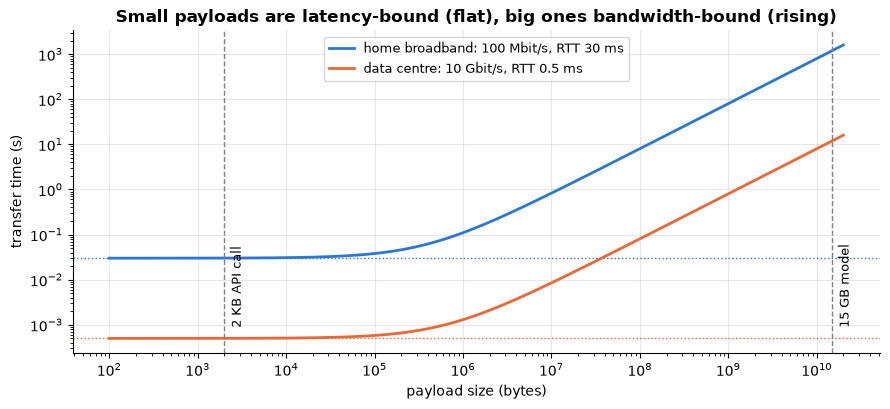

home broadband: 100 Mbit/s, RTT 30 ms    2 KB:    30.16 ms | 15 GB:  1200.0 s
data centre: 10 Gbit/s, RTT 0.5 ms       2 KB:     0.50 ms | 15 GB:    12.0 s


In [19]:
sizes = np.logspace(2, 10.3, 200)                              # 100 bytes ... ~20 GB
links = {"home broadband: 100 Mbit/s, RTT 30 ms": (100e6, 0.030),
         "data centre: 10 Gbit/s, RTT 0.5 ms": (10e9, 0.0005)}
plt.figure(figsize=(9, 4.2))
for (label, (bw, rtt)), c in zip(links.items(), PALETTE):
    plt.loglog(sizes, rtt + sizes * 8 / bw, label=label, color=c)
    plt.axhline(rtt, color=c, ls=":", lw=1)
for size, name in [(2e3, "2 KB API call"), (1.5e10, "15 GB model")]:
    plt.axvline(size, color="grey", ls="--", lw=1); plt.text(size * 1.15, 1e-3, name, rotation=90, fontsize=9)
plt.xlabel("payload size (bytes)"); plt.ylabel("transfer time (s)")
plt.title("Small payloads are latency-bound (flat), big ones bandwidth-bound (rising)"); plt.legend(fontsize=9)
plt.tight_layout(); plt.show()
for label, (bw, rtt) in links.items():
    print(f"{label:<40} 2 KB: {(rtt + 2e3 * 8 / bw) * 1000:8.2f} ms | 15 GB: {rtt + 1.5e10 * 8 / bw:7.1f} s")

**What just happened?** For a 2 KB API call, the data-centre link is ~60x faster purely because of latency (30 ms vs 0.5 ms RTT); for the 15 GB model the 100x bandwidth difference dominates (20 minutes vs 12 seconds). This is why you put your app server **next to** the model server, and download weights once into a cache or image rather than at every start-up.

### Measuring round trips on localhost, and why connection reuse matters

Each new TCP connection costs a handshake (and with TLS, another round trip plus crypto). Creating a new HTTP client per request also rebuilds its connection pool and TLS context. We measure 50 requests each way against the local server, plus the raw TCP connect time, and look at the **tail** (p95/p99), because users feel the slow requests, not the average.

                            p50 ms  p95 ms  p99 ms
TCP connect only              0.09    0.18    0.32
new client per request       91.25  361.17  410.08
reused client (keep-alive)    8.90   24.43   32.98


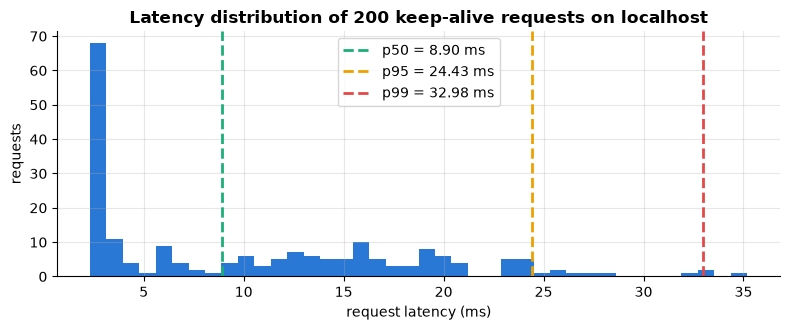

In [20]:
def pct(xs, q):
    return float(np.percentile(xs, q))

port = free_port()
with run_server(uvicorn_cmd(port), port) as base:
    connect_ms, fresh_ms, reuse_ms = [], [], []
    for _ in range(50):
        t = time.perf_counter(); socket.create_connection(("127.0.0.1", port)).close()
        connect_ms.append((time.perf_counter() - t) * 1000)
    for _ in range(50):                                       # anti-pattern: a new client per request
        t = time.perf_counter()
        with client(base) as c:
            c.get("/health")
        fresh_ms.append((time.perf_counter() - t) * 1000)
    with client(base) as c:                                   # good: one client, keep-alive connection
        c.get("/health")                                      # warm-up: opens the connection once
        for _ in range(200):
            t = time.perf_counter(); c.get("/health"); reuse_ms.append((time.perf_counter() - t) * 1000)

stats = pd.DataFrame({name: {"p50 ms": pct(v, 50), "p95 ms": pct(v, 95), "p99 ms": pct(v, 99)}
                      for name, v in [("TCP connect only", connect_ms), ("new client per request", fresh_ms),
                                      ("reused client (keep-alive)", reuse_ms)]}).T.round(2)
print(stats)
plt.figure(figsize=(8, 3.4))
plt.hist(reuse_ms, bins=40, color=PALETTE[0])
for q, c in [(50, PALETTE[2]), (95, PALETTE[3]), (99, PALETTE[7])]:
    plt.axvline(pct(reuse_ms, q), color=c, ls="--", label=f"p{q} = {pct(reuse_ms, q):.2f} ms")
plt.xlabel("request latency (ms)"); plt.ylabel("requests"); plt.legend()
plt.title("Latency distribution of 200 keep-alive requests on localhost"); plt.tight_layout(); plt.show()
assert stats.loc["reused client (keep-alive)", "p50 ms"] < stats.loc["new client per request", "p50 ms"]

**What just happened?** Even on loopback (no real network), reusing one client is clearly faster at the median than building a new client and connection for every request. A new `httpx.Client` also loads the CA certificate bundle and builds a TLS context, which is surprisingly expensive (your exact milliseconds depend on how busy the machine is); across a real network with TLS the gap is a full extra round trip or two per request. The histogram shows a typical latency **long tail**: most requests are fast, a few are much slower (garbage collection, scheduling, other processes). SLOs are therefore written in percentiles ("p99 < 300 ms"), not averages.

> ⚠️ **Common mistake:** calling `httpx.get(...)` / `requests.get(...)` inside a loop or per web request. Create one `httpx.Client` / `AsyncClient` (or `requests.Session`) at start-up and reuse it.

### Timeouts and retries

Every network call needs a **timeout**; without one, a hung server hangs your program forever (`requests` has *no* default timeout; httpx defaults to 5 s). httpx separates **connect** (establishing TCP/TLS), **read** (waiting for data), **write** and **pool** (waiting for a free connection) timeouts. LLM calls need a generous *read* timeout but a short *connect* timeout.

**Retries** recover from transient failures, but only when safe:
- retry **idempotent** requests (GET, PUT, DELETE, or POST with an idempotency key), on **429, 502, 503, 504** and connection errors; never on 400/401/403/404/422 (retrying won't fix them);
- wait with **exponential backoff** (0.1 s, 0.2 s, 0.4 s, ...) plus **random jitter**, so a thousand clients don't retry in lock-step and knock the server over again (the "thundering herd"); honour `Retry-After`;
- cap the attempts and the total time; after repeated failures a **circuit breaker** stops calling a dead dependency for a while.

In [21]:
RETRYABLE = {429, 502, 503, 504}

def get_with_retries(c, url, rng, max_attempts=4, base=0.1, cap=2.0, **kw):
    """GET with exponential backoff + full jitter; honours Retry-After."""
    for attempt in range(1, max_attempts + 1):
        try:
            r = c.get(url, **kw)
            if r.status_code not in RETRYABLE:
                return r, attempt                              # success, or an error retrying can't fix
            reason, retry_after = f"HTTP {r.status_code}", r.headers.get("retry-after")
        except (httpx.ConnectError, httpx.ReadTimeout) as e:
            reason, retry_after = type(e).__name__, None
        if attempt == max_attempts:
            raise RuntimeError(f"giving up after {attempt} attempts ({reason})")
        delay = float(retry_after) if retry_after else rng.uniform(0, min(cap, base * 2 ** (attempt - 1)))
        print(f"    attempt {attempt}: {reason} -> waiting {delay:.3f} s")
        time.sleep(delay)

port = free_port()
with run_server(uvicorn_cmd(port), port) as base:
    with client(base, timeout=httpx.Timeout(5.0, read=0.5)) as c:     # 0.5 s read timeout, 5 s for the rest
        t = time.perf_counter()
        try:
            c.get("/v1/slow", params={"seconds": 2})
        except httpx.ReadTimeout:
            print(f"/v1/slow (2 s) with a 0.5 s read timeout -> ReadTimeout after {time.perf_counter() - t:.2f} s")
        print(f"/v1/slow (0.1 s) -> {c.get('/v1/slow', params={'seconds': 0.1}).json()}")

    with client(base) as c:
        print("calling /v1/flaky (fails twice with 503, then recovers):")
        r, attempts = get_with_retries(c, "/v1/flaky", rng=random.Random(0), headers={"X-Client-Id": "demo"})
        print(f"    -> {r.status_code} {r.json()} after {attempts} attempts")

/v1/slow (2 s) with a 0.5 s read timeout -> ReadTimeout after 0.56 s
/v1/slow (0.1 s) -> {'waited': 0.1}


calling /v1/flaky (fails twice with 503, then recovers):
    attempt 1: HTTP 503 -> waiting 0.084 s
    attempt 2: HTTP 503 -> waiting 0.152 s


    -> 200 {'ok': True, 'attempt': 3} after 3 attempts


**What just happened?** The read timeout cut the 2-second call off after about 0.5 s instead of letting it hang, while the fast call went through under the same settings. The flaky endpoint failed twice with **503**; our client waited a short, random, growing delay each time and succeeded on the 3rd attempt.

### Load balancers, reverse proxies and CDNs

```
users ──> CDN edge (cache static files, TLS, DDoS / rate limits)
             └──> load balancer (L4 or L7) ──> reverse proxy (nginx) ──> app servers (uvicorn) ──> model servers (GPU)
```

- A **reverse proxy** sits in front of your app servers: TLS termination, routing by path/host, compression, request-size limits, buffering, caching, and protection of the app from slow clients. nginx, Envoy, Traefik and Caddy are common.
- A **load balancer** spreads requests over healthy backends (it runs **health checks**, e.g. `GET /health`). **L4** balancers forward TCP connections (fast, protocol-agnostic); **L7** balancers understand HTTP and can route by path, header or cookie. Algorithms: round robin, **least connections** (good when request durations vary wildly, as with LLM generation), weighted, and hashing (sticky sessions; for LLM serving, routing requests that share a prompt prefix to the same replica lets it reuse its KV cache).
- A **CDN** (content delivery network) caches content at edge locations close to users, so static assets and large public files (front-end bundles, model weights, datasets) don't cross an ocean each time.

A typical nginx config for an LLM API (shown as text; not run here):

```nginx
limit_req_zone $binary_remote_addr zone=api:10m rate=10r/s;    # rate limiting at the edge

upstream llm_backend {
    least_conn;                                  # LLM requests have very different durations
    server 10.0.1.11:8000;
    server 10.0.1.12:8000;
}
server {
    listen 443 ssl;
    server_name api.example.com;
    ssl_certificate     /etc/ssl/certs/api.pem;
    ssl_certificate_key /etc/ssl/private/api.key;
    client_max_body_size 10m;

    location /v1/ {
        limit_req zone=api burst=20 nodelay;
        limit_req_status 429;                    # nginx's default would be 503
        proxy_pass http://llm_backend;
        proxy_set_header Host $host;
        proxy_set_header X-Forwarded-For $proxy_add_x_forwarded_for;
        proxy_set_header X-Forwarded-Proto $scheme;
        proxy_read_timeout 300s;                 # generations can take minutes
        proxy_buffering off;                     # forward SSE tokens immediately
    }
    location /v1/ws/ {
        proxy_pass http://llm_backend;
        proxy_http_version 1.1;                  # WebSockets need the upgrade headers passed on
        proxy_set_header Upgrade $http_upgrade;
        proxy_set_header Connection "upgrade";
    }
}
```

### Rate limiting with a token bucket

Rate limits protect expensive backends (GPUs!) and enforce fair use; LLM providers limit requests *and* tokens per minute and answer **429** with `Retry-After`. The most common algorithm is the **token bucket**: a bucket holds up to `capacity` tokens and refills at `rate` tokens per second; each request spends one token or is rejected. It allows short **bursts** up to the capacity while enforcing the average rate. Our app's limiter (written earlier to `ratelimit.py`) is exactly this; first we simulate it with a fake clock:

In [22]:
sys.path.insert(0, str(WORK))
from ratelimit import TokenBucket
sys.path.remove(str(WORK))

bucket = TokenBucket(capacity=5, rate=1.0)                 # bursts of 5, then 1 request per second
times = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 1.6, 1.7, 4.0, 4.1, 4.2]
trace = []
for t in times:
    ok, wait = bucket.allow(t)
    trace.append({"t (s)": t, "allowed": ok, "tokens left": round(bucket.tokens, 2),
                  "retry after (s)": round(wait, 2) if not ok else ""})
print(pd.DataFrame(trace).to_string(index=False))

 t (s)  allowed  tokens left retry after (s)
   0.0     True          4.0                
   0.1     True          3.1                
   0.2     True          2.2                
   0.3     True          1.3                
   0.4     True          0.4                
   0.5    False          0.5             0.5
   0.6    False          0.6             0.4
   1.6     True          0.6                
   1.7    False          0.7             0.3
   4.0     True          2.0                
   4.1     True          1.1                
   4.2     True          0.2                


**What just happened?** The first five requests (t = 0-0.4 s) were allowed as a burst. At t = 0.5 and 0.6 s less than one token was left, so they were rejected with a suggested wait. By t = 1.6 s refilling had produced a whole token again (one more request allowed, the next one rejected), and after the pause until t = 4.0 s the bucket had refilled enough for another burst. Now against the live server, 8 requests in quick succession:

In [23]:
port = free_port()
with run_server(uvicorn_cmd(port), port) as base, client(base) as c:
    results = [c.get("/v1/limited", headers={"X-Client-Id": "burst-test"}) for _ in range(8)]
    print("status codes:", [r.status_code for r in results])
    rejected = [r for r in results if r.status_code == 429]
    print("a rejected response:", rejected[0].headers["retry-after"], "s Retry-After |", rejected[0].json()["detail"])
    print("another client is unaffected:", c.get("/v1/limited", headers={"X-Client-Id": "someone-else"}).status_code)

status codes: [200, 200, 200, 200, 200, 429, 429, 429]
a rejected response: 1 s Retry-After | rate limit exceeded
another client is unaffected: 200


**What just happened?** The first 5 requests passed (the burst), the remaining 3 got **429** with `Retry-After: 1`, and a different client had its own bucket. In production, limits usually live at the edge (API gateway, nginx, CDN) and the counters in a shared store such as Redis, so that all replicas enforce one limit.

### Webhooks

A **webhook** is a reverse API call: instead of you polling "is my fine-tuning job done yet?" every 10 seconds, the provider sends an HTTP `POST` to *your* URL when the event happens. Because anyone on the internet can POST to that URL, you must **verify** each call. Standard practice (Stripe, GitHub, OpenAI and others): the provider signs `timestamp + body` with a shared secret using **HMAC-SHA256**, and you recompute and compare in constant time, and reject old timestamps (replays).

In [24]:
WEBHOOK_SECRET = b"whsec_demo_only_not_a_real_secret"

def sign(body: bytes, timestamp: int) -> str:
    return hmac.new(WEBHOOK_SECRET, f"{timestamp}.".encode() + body, hashlib.sha256).hexdigest()

def verify(body: bytes, timestamp: int, signature: str, now: int, tolerance_s=300):
    if abs(now - timestamp) > tolerance_s:
        return "rejected: timestamp outside tolerance (possible replay)"
    if not hmac.compare_digest(sign(body, timestamp), signature):     # constant-time comparison
        return "rejected: signature mismatch"
    return "accepted"

now = 1_800_000_000                                          # a fixed 'current time' for a reproducible demo
body = json.dumps({"event": "fine_tune.succeeded", "job_id": "ft-123", "model": "tiny-bert-ft"}).encode()
sig = sign(body, now - 5)                                    # what the provider sends in a header
print("genuine delivery         ->", verify(body, now - 5, sig, now))
print("body tampered in transit ->", verify(body.replace(b"ft-123", b"ft-999"), now - 5, sig, now))
print("replayed an hour later   ->", verify(body, now - 5, sig, now + 3600))
print("forged by an attacker    ->", verify(body, now, "0" * 64, now))

genuine delivery         -> accepted
body tampered in transit -> rejected: signature mismatch
replayed an hour later   -> rejected: timestamp outside tolerance (possible replay)
forged by an attacker    -> rejected: signature mismatch


**What just happened?** Only the genuine delivery was accepted. Changing one character of the body broke the signature; replaying a captured delivery an hour later failed the timestamp check; a made-up signature failed too. Also: respond `2xx` quickly and do the real work in a background job (providers retry when you are slow or return errors, so make your handler **idempotent** using the event ID).

## 12. Troubleshooting checklist

**In plain English:** when a call fails, find which step broke: the name lookup, the connection, the security check, or the reply.

When "the API doesn't work", find the **layer** that fails. First, `curl -v` shows every step: name resolution, TCP connect, (TLS handshake), request headers (`>`) and response headers (`<`):

In [25]:
port = free_port()
with run_server(uvicorn_cmd(port), port) as base:
    if shutil.which("curl"):
        r = subprocess.run(["curl", "-v", "-sS", "--noproxy", "*", f"{base}/health"],
                           capture_output=True, text=True, env=SAFE_ENV, timeout=10)
        verbose = [l for l in r.stderr.splitlines() if not l.startswith("{")]
        print(redact("\n".join(re.sub(r"(< date:).*", r"\1 <now>", l) for l in verbose)))
        print("body:", r.stdout)
    else:
        print("curl not installed: skipping")
    ss = subprocess.run(["ss", "-ltn", f"sport = :{port}"], capture_output=True, text=True, env=SAFE_ENV) \
        if shutil.which("ss") else None
    if ss:
        print(f"$ ss -ltn 'sport = :{port}'   # who is listening on that port?\n" + ss.stdout.strip())

*   Trying 127.0.0.1:8206...
* Connected to 127.0.0.1 (127.0.0.1) port 8206
> GET /health HTTP/1.1
> Host: 127.0.0.1:8206
> User-Agent: curl/8.5.0
> Accept: */*
> 
< HTTP/1.1 200 OK
< date: <now>
< server: uvicorn
< content-length: 15
< content-type: application/json
< 
* Connection #0 to host 127.0.0.1 left intact
body: {"status":"ok"}
$ ss -ltn 'sport = :8206'   # who is listening on that port?
State  Recv-Q Send-Q Local Address:Port Peer Address:PortProcess
LISTEN 0      2048       127.0.0.1:8206      0.0.0.0:*


Now the three classic failures, reproduced safely on localhost:

In [26]:
# 1) Connection refused: the machine answered, but nothing listens on that port (layer 4 'RST')
port = free_port()
t = time.perf_counter()
try:
    socket.create_connection(("127.0.0.1", port), timeout=3)
except ConnectionRefusedError as e:
    print(f"1) nothing listening      -> ConnectionRefusedError ({e.strerror}) after {(time.perf_counter() - t) * 1000:.1f} ms")

# 2) Timeout: the connection is accepted (by the kernel's backlog) but the server never answers
port = free_port()
mute = socket.socket(); mute.bind(("127.0.0.1", port)); mute.listen()   # listens, never accept()s or replies
try:
    t = time.perf_counter()
    try:
        httpx.get(f"http://127.0.0.1:{port}/health", timeout=httpx.Timeout(3.0, read=0.5), trust_env=False)
    except httpx.ReadTimeout:
        print(f"2) server never responds  -> httpx.ReadTimeout after {time.perf_counter() - t:.2f} s")
finally:
    mute.close()

# 3) Address already in use: a second server tries to bind the same port
port = free_port()
first = socket.socket(); first.bind(("127.0.0.1", port)); first.listen()
second = socket.socket()
try:
    second.bind(("127.0.0.1", port))
except OSError as e:
    print(f"3) port taken             -> OSError [Errno {e.errno}] {errno.errorcode[e.errno]}: {e.strerror}")
finally:
    first.close(); second.close()

1) nothing listening      -> ConnectionRefusedError (Connection refused) after 1.5 ms


2) server never responds  -> httpx.ReadTimeout after 0.87 s
3) port taken             -> OSError [Errno 98] EADDRINUSE: Address already in use


**What just happened?** **Refused** came back almost instantly: the kernel replied "no one here" (a TCP reset). The **timeout** took about as long as the 0.5 s read timeout we set, because nobody ever replied. On a real network a *connect* timeout usually means packets are silently dropped: a firewall or cloud security group, a wrong IP, or a server that's down hard. **EADDRINUSE** means another process (often an old copy of your own server) already holds the port.

| Symptom | Likely cause | What to run / check |
|---|---|---|
| `Name or service not known` / `gaierror` | DNS: typo in host, no DNS inside the container, VPN | `getent hosts NAME`, `dig NAME`, `/etc/resolv.conf` |
| `Connection refused` (instant) | server not running, wrong port, or bound to `127.0.0.1` while you connect from another machine/container | `ss -ltnp`, `curl -v`, server logs, bind address |
| connect **timeout** | firewall / security group drops packets, wrong IP, server overloaded | security-group rules, `curl -v --connect-timeout 5`, `traceroute` |
| read timeout | server accepted but is slow (long generation, deadlock, overloaded GPU) | server logs, increase *read* timeout, stream the response |
| `Address already in use` | old process still running, two apps on one port | `ss -ltnp 'sport = :8000'` or `lsof -i :8000`, then stop that PID |
| `SSL: CERTIFICATE_VERIFY_FAILED` | self-signed/corporate CA, wrong hostname, expired cert, clock skew | `openssl s_client -connect host:443 -servername host`; fix the CA bundle, **don't** disable verification |
| 401 / 403 | missing/wrong key / key without permission | the `Authorization` header actually sent (`curl -v`) |
| 404 | wrong path or version prefix, missing trailing slash, proxy routing | the exact URL; `/docs` of a FastAPI app |
| 413 / 431 | body / headers too large | proxy `client_max_body_size` |
| 429 | rate limited | `Retry-After`, backoff, request a higher quota |
| 502 / 504 from the proxy | backend crashed / slower than the proxy timeout | backend logs, `proxy_read_timeout`, health checks |
| CORS error in the browser console only | missing/incorrect `Access-Control-Allow-*` headers | the preflight `OPTIONS` response in the browser's network tab |
| works locally, not in Docker | server bound to `127.0.0.1` inside the container, or `localhost` means the container itself | bind `0.0.0.0` in the container; use service names / `host.docker.internal` |

## 🔗 How this connects to modern AI

| Networking idea | Where you meet it in AI engineering |
|---|---|
| SSE streaming | every chat UI that shows tokens as they're generated (OpenAI-style and Anthropic APIs, vLLM, Ollama, TGI) |
| WebSockets | realtime voice agents, "stop generating", collaborative notebooks |
| gRPC / HTTP/2 | Triton Inference Server and TF Serving gRPC endpoints, internal feature-store and embedding services |
| timeouts, retries, idempotency keys | robust LLM clients (rate-limit 429s, overloaded 503/529-style errors), safe retries of expensive jobs |
| token-bucket rate limits | provider limits in requests *and* tokens per minute; protecting your own GPU servers |
| load balancing, least connections, prefix-aware routing | LLM serving clusters where requests vary from 10 ms to minutes |
| webhooks + HMAC | notifications when fine-tuning, batch inference or evaluation jobs finish |
| CORS | connecting a React/Next.js front-end to your FastAPI model API |
| CIDR, private subnets | VPCs for GPU clusters and private model endpoints |
| latency vs. bandwidth | placing app servers next to model servers; caching model weights instead of downloading them at start-up |

Related notebooks: [FastAPI intro](../12_FastAPI/01_fastapi_intro.ipynb), [advanced FastAPI](../12_FastAPI/02_advanced_fastapi.ipynb), [a production ML API](../12_FastAPI/04_industry_production_ml_api.ipynb), [deployment concepts](../16_Deployment/01_deployment_concepts.ipynb), [Docker basics](../17_Docker/01_docker_basics.ipynb), [AWS for AI](../18_Cloud/01_aws_for_ai.ipynb), [LLM application patterns](../08_LLM/20_industry_llm_application_patterns.ipynb).

## Recap

- Networks are layered: **application** (HTTP, DNS) over **transport** (TCP/UDP, ports) over **network** (IP addresses) over **link**. Diagnose failures layer by layer.
- **IPv4** = 32 bits, **IPv6** = 128 bits; private ranges 10/8, 172.16/12, 192.168/16; **CIDR** `/n` leaves 32 - n host bits. Bind `127.0.0.1` for local-only, `0.0.0.0` for all interfaces (needed inside containers).
- **DNS** resolves names via a cached hierarchy (root → TLD → authoritative) with TTLs.
- **TCP** = reliable, ordered **byte stream** after a 3-way handshake (you must frame messages); **UDP** = independent datagrams, no guarantees.
- **HTTP**: methods (safe / idempotent), status codes (4xx client, 5xx server), headers, cookies, keep-alive; HTTP/2 multiplexes over TCP, HTTP/3 runs over QUIC/UDP. On the wire, HTTP/1.x is just text.
- **TLS** gives confidentiality, integrity and **authentication**; the last depends on certificate verification, so never disable it; trust a private CA explicitly instead.
- **REST**: resources + verbs, idempotency keys for POST retries, cursor pagination, versioned paths, RFC 9457 problem-details errors.
- **Streaming**: SSE (one-way, text events, how LLMs stream tokens), WebSockets (full duplex after an HTTP upgrade), gRPC (HTTP/2 + protobuf).
- **CORS** is a browser-enforced opt-in for cross-origin reads, not API security.
- Reuse connections; set **timeouts**; retry only idempotent requests on 429/5xx with **exponential backoff + jitter**; rate-limit with a **token bucket**; verify **webhooks** with HMAC and timestamps.
- Refused = nothing listening (fast); timeout = no answer; EADDRINUSE = port already taken; `curl -v` shows each step.

## Practice problems

**1. (Easy)** How many usable hosts does a `/27` subnet have? Is `10.0.4.17` inside `10.0.0.0/22`?
<details><summary>Show solution</summary>

A /27 leaves 32 - 27 = 5 host bits: 2^5 = 32 addresses, minus network and broadcast = **30 usable hosts**. `10.0.0.0/22` covers 2^10 = 1024 addresses, **10.0.0.0 - 10.0.3.255**, so `10.0.4.17` is **not** inside it.

```python
import ipaddress

net = ipaddress.ip_network("10.0.0.0/27")
print(net.num_addresses, net.num_addresses - 2)                    # 32 addresses, 30 usable hosts
print(ipaddress.ip_address("10.0.4.17") in ipaddress.ip_network("10.0.0.0/22"))   # False
print(ipaddress.ip_network("10.0.0.0/22")[-1])                     # last address: 10.0.3.255
```

</details>

**2. (Easy, exam-style)** Choose the status code: (a) a model was registered; (b) the request JSON is valid but `accuracy` is 1.7; (c) no API key was sent; (d) the key is valid but may not use that model; (e) the client exceeded its quota; (f) nginx can't reach the crashed model server; (g) the model is still loading.
<details><summary>Show solution</summary>

(a) **201 Created** (with `Location`); (b) **422 Unprocessable Content** (some APIs use 400); (c) **401 Unauthorized**; (d) **403 Forbidden**; (e) **429 Too Many Requests** with `Retry-After`; (f) **502 Bad Gateway**; (g) **503 Service Unavailable**, ideally with `Retry-After`.

</details>

**3. (Medium, conceptual)** Your client sends `POST /v1/fine-tunes` (costs $500). The request times out after 30 s. Is it safe to retry? Why, and how do you make it safe?
<details><summary>Show solution</summary>

Not by default. A timeout tells you that *you* stopped waiting, not that the server didn't act: the job may have been created and only the response was lost. POST isn't idempotent, so a blind retry can start a second $500 job. Make it safe with an **idempotency key**: generate a unique key per *logical* operation (e.g. a UUID stored with your request), send it as `Idempotency-Key`, and have the server store key → result, returning the original result for repeats (as our `/v1/models` endpoint does). Alternatively, check for existing jobs by a client-supplied unique name before retrying.

</details>

**4. (Medium)** Estimate the time to download a 4 GB model over 200 Mbit/s with an 80 ms RTT, and to send a 2 KB request on the same link. Which one is latency-bound?
<details><summary>Show solution</summary>

```python
def transfer_time(size_bytes, bandwidth_bits_per_s, rtt_s):
    """Simple model: one round trip to ask, then the bytes at full speed."""
    return rtt_s + size_bytes * 8 / bandwidth_bits_per_s

print(round(transfer_time(4e9, 200e6, 0.080), 1), "s for a 4 GB model")   # 160.1 s
print(round(transfer_time(2_000, 200e6, 0.080) * 1000, 2), "ms for a 2 KB request")   # 80.08 ms
```
4 GB = 32 Gbit / 0.2 Gbit/s = 160 s (+0.08 s): **bandwidth-bound**. The 2 KB request takes ~80.08 ms, of which 80 ms is the round trip: **latency-bound**; a faster link wouldn't help it, being closer to the server would.

</details>

**5. (Medium, coding)** Without the `ipaddress` module, write `cidr_overlap(a, b)` that tells whether two IPv4 CIDR blocks overlap (essential when peering two VPCs). Test it against `ipaddress`.
<details><summary>Show solution</summary>

```python
def parse_ipv4(s):
    a, b, c, d = (int(x) for x in s.split("."))
    return (a << 24) | (b << 16) | (c << 8) | d          # 4 bytes -> one 32-bit integer

def cidr_range(cidr):
    ip, prefix = cidr.split("/")
    mask = (0xFFFFFFFF << (32 - int(prefix))) & 0xFFFFFFFF  # prefix ones, then zeros
    first = parse_ipv4(ip) & mask                           # network address
    last = first | (~mask & 0xFFFFFFFF)                     # broadcast address
    return first, last

def cidr_overlap(a, b):
    a1, a2 = cidr_range(a)
    b1, b2 = cidr_range(b)
    return a1 <= b2 and b1 <= a2                            # two intervals overlap

print(cidr_overlap("10.0.0.0/16", "10.0.128.0/20"), cidr_overlap("10.0.0.0/22", "10.0.4.0/22"))  # True False
```
Each block is an integer interval [network address, broadcast address]; two intervals overlap when each starts before the other ends. Tested on 3000 random pairs against `ip_network(a).overlaps(ip_network(b))`.

</details>

**6. (Medium, coding)** Write `backoff_delays(attempts, base, cap, rng)` that returns the "full jitter" delays: attempt k waits a uniformly random time in [0, min(cap, base · 2^k)]. Why is jitter better than a fixed exponential schedule?
<details><summary>Show solution</summary>

```python
import random

def backoff_delays(attempts, base=0.5, cap=30.0, rng=None):
    """'Full jitter' exponential backoff: wait a random time in [0, min(cap, base * 2**k)]."""
    rng = rng or random.Random()
    return [rng.uniform(0, min(cap, base * 2 ** k)) for k in range(attempts)]

print([round(d, 2) for d in backoff_delays(6, rng=random.Random(1))])
```
Without jitter, all clients that failed at the same moment (e.g. during a brief outage) retry at exactly the same moments too, creating synchronised traffic spikes that can knock the recovering server down again (the thundering herd). Randomising spreads the retries out. Tested: every delay is within its bound, and the average of attempt 4 with base 1 is ~8 s (the mean of U(0, 16)).

</details>

**7. (Medium, conceptual)** Your React app at `http://localhost:3000` calls your FastAPI backend at `http://localhost:8000/v1/models` with `fetch` and gets a CORS error in the browser console, but the same request works with `curl`. Explain, and fix it properly.
<details><summary>Show solution</summary>

Different ports make different **origins**, so the browser applies the same-origin policy. Because the request sends `Content-Type: application/json` (and maybe `Authorization`), the browser first sends a **preflight `OPTIONS`**; the backend doesn't answer it with `Access-Control-Allow-Origin: http://localhost:3000` (and the allowed methods/headers), so the browser blocks the call. `curl` isn't a browser and ignores CORS. Fix: add `CORSMiddleware` with `allow_origins=["http://localhost:3000"]` (plus your production front-end origin), the methods and headers you use, and `allow_credentials=True` only if you use cookies (never with `"*"`). Don't "fix" it with `allow_origins=["*"]` in production, and remember CORS doesn't replace authentication.

</details>

**8. (Hard, troubleshooting)** Ollama runs on your laptop at `127.0.0.1:11434`. Your app in a Docker container calls `http://localhost:11434` and gets `Connection refused`. Your colleague changes it to the laptop's LAN IP and gets a **timeout** instead. Explain both errors and give a working setup.
<details><summary>Show solution</summary>

Inside the container, `localhost` is the **container's own** loopback (it has its own network namespace), where nothing listens on 11434, so the kernel answers immediately: **refused**. With the LAN IP the packets do leave the container, but Ollama is bound to `127.0.0.1` on the host, so it only accepts loopback connections; depending on the firewall, the packets are either rejected or (commonly) silently dropped, giving a **timeout**. Working options: use `http://host.docker.internal:11434` (built into Docker Desktop; on Linux add `--add-host=host.docker.internal:host-gateway`) **and** make Ollama listen on an address the container can reach (e.g. `OLLAMA_HOST=0.0.0.0`, firewalled to local use only); or, better, run Ollama as a second container on the same Docker network and call it by service name (`http://ollama:11434`). Check each step with `curl -v` from inside the container.

</details>

## Further reading

- Kurose & Ross, *Computer Networking: A Top-Down Approach*, 8th ed.: Ch. 1 (layers), 2 (HTTP, DNS, sockets), 3 (TCP/UDP, congestion control), 4-5 (IP, routing, CIDR), 8 (security, TLS).
- Tanenbaum, Feamster & Wetherall, *Computer Networks*, 6th ed.
- Ilya Grigorik, [*High Performance Browser Networking*](https://hpbn.co/) (free online): latency, TCP, TLS, HTTP/2, WebSockets, SSE.
- [MDN Web Docs: HTTP](https://developer.mozilla.org/en-US/docs/Web/HTTP) (methods, status codes, CORS, SSE) and RFC 9110 (HTTP Semantics), RFC 9457 (Problem Details), RFC 6455 (WebSocket).

## Next notebook

Continue with [Security for AI applications](08_security_for_ai_applications.ipynb). Previous: [Operating systems for developers](06_operating_systems_for_developers.ipynb).

In [27]:
# Clean up: prove every server we started has exited, then delete the sandbox
alive = [p.pid for p in STARTED if p.poll() is None]
print(f"servers started: {len(STARTED)} | still running: {len(alive)}")
assert not alive
shutil.rmtree(WORK, ignore_errors=True)
print("sandbox removed:", not WORK.exists())

servers started: 9 | still running: 0
sandbox removed: True
